
# Extended Hyperparameter Tuning with Strict Nested Cross-Validation

## Research Objectives

1. Tune and compare five machine learning regression algorithms.
2. Compare Original G8 and ln(G8).
3. Evaluate generalization using strict nested cross-validation.
4. Examine model complexity and overfitting.
5. Select a final model for subsequent SHAP analysis.

## Experimental Principles

- Outer CV is used only for model evaluation.
- Inner CV selects algorithms, target transformations and hyperparameters.
- Data-dependent preprocessing is fitted within training folds.
- MAE is evaluated on the original salary scale (RM).
- The held-out test set is excluded from model selection.
- All searched configurations and results will be saved.
- This is an extended experiment informed by earlier exploratory results.


In [1]:

# ============================================================
# Section 1 - Formal Experiment Configuration
# ============================================================

import json
import hashlib
import sys
from pathlib import Path
from importlib.metadata import version
from sklearn.model_selection import ParameterGrid

# ------------------------------------------------------------
# 1. Locate original data
# ------------------------------------------------------------

possible_paths = [
    Path("../data/fulldata.csv"),
    Path("data/fulldata.csv")
]

data_path = next(
    (p.resolve() for p in possible_paths if p.exists()),
    None
)

if data_path is None:
    raise FileNotFoundError(
        "Cannot find data/fulldata.csv"
    )

project_root = data_path.parent.parent

# ------------------------------------------------------------
# 2. Experiment identity
# ------------------------------------------------------------

EXPERIMENT_ID = "extended_nested_cv_v1"

OUTPUT_DIR = (
    project_root
    / "results"
    / "week6"
    / "extended_nested_cv"
    / "v1"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 3. Fixed experimental protocol
# ------------------------------------------------------------

PROTOCOL = {
    "experiment_id": EXPERIMENT_ID,
    "data_file": "fulldata.csv",
    "target": "G8_Total_salaries_and_wages",
    "excluded_columns": [
        "G14_Total_salaries_and_wages_includes_overtime",
        "Weight"
    ],
    "features": [
        "State",
        "Strata",
        "Sex",
        "Age",
        "Ethnic_Group",
        "Marital_Status",
        "Educational_Attainment",
        "Occupation_Group",
        "Industry_Section"
    ],
    "test_size": 0.20,
    "split_seed": 42,
    "outer_folds": 5,
    "outer_seed": 2026,
    "inner_folds": 3,
    "inner_seed": 2027,
    "search_seed": 42,
    "models": [
        "Decision Tree",
        "Random Forest",
        "XGBoost",
        "LightGBM",
        "CatBoost"
    ],
    "target_options": [
        "Original G8",
        "ln(G8)"
    ],
    "primary_metric": "MAE",
    "secondary_metrics": [
        "RMSE",
        "R2"
    ],
    "search_budget": {
        "Decision Tree": 20,
        "Random Forest": 24,
        "XGBoost": 24,
        "LightGBM": 24,
        "CatBoost": 24
    },
    "n_jobs_search": 1
}

# ------------------------------------------------------------
# 4. Predefine search spaces
# ------------------------------------------------------------

SEARCH_SPACES = {
    "Decision Tree": {
        "max_depth": [6, 10, 16, 24, None],
        "min_samples_leaf": [5, 10, 20, 40]
    },

    "Random Forest": {
        "n_estimators": [200, 400, 700],
        "max_depth": [12, 24, None],
        "min_samples_leaf": [1, 3, 7, 15],
        "max_features": [0.5, 0.8, 1.0]
    },

    "XGBoost": {
        "n_estimators": [300, 600, 1000],
        "learning_rate": {
            "distribution": "loguniform",
            "low": 0.015,
            "high": 0.20
        },
        "max_depth": [3, 5, 7],
        "min_child_weight": [1, 3, 10],
        "subsample": [0.7, 0.85, 1.0],
        "colsample_bytree": [0.7, 0.85, 1.0]
    },

    "LightGBM": {
        "n_estimators": [300, 600, 1000],
        "learning_rate": {
            "distribution": "loguniform",
            "low": 0.015,
            "high": 0.20
        },
        "num_leaves": [15, 31, 63],
        "min_child_samples": [10, 30, 60],
        "max_depth": [-1, 8, 12]
    },

    "CatBoost": {
        "iterations": [300, 600, 900, 1200],
        "depth": [4, 6, 8, 10],
        "learning_rate": {
            "distribution": "loguniform",
            "low": 0.015,
            "high": 0.20
        },
        "l2_leaf_reg": {
            "distribution": "loguniform",
            "low": 0.5,
            "high": 30.0
        }
    }
}

# ------------------------------------------------------------
# 5. Dataset fingerprint
# ------------------------------------------------------------

hasher = hashlib.sha256()

with open(data_path, "rb") as f:
    for chunk in iter(lambda: f.read(1024 * 1024), b""):
        hasher.update(chunk)

DATA_SHA256 = hasher.hexdigest()

experiment_config = {
    "protocol": PROTOCOL,
    "search_spaces": SEARCH_SPACES,
    "data_sha256": DATA_SHA256
}

# ------------------------------------------------------------
# 6. Save configuration without silent overwriting
# ------------------------------------------------------------

config_path = OUTPUT_DIR / "experiment_config.json"

if config_path.exists():

    with open(config_path, "r", encoding="utf-8") as f:
        saved_config = json.load(f)

    if saved_config != experiment_config:
        raise RuntimeError(
            "Experiment configuration has changed. "
            "Use a new experiment version instead "
            "of overwriting existing results."
        )

    print("Existing experiment configuration verified.")

else:

    with open(config_path, "w", encoding="utf-8") as f:
        json.dump(
            experiment_config,
            f,
            indent=4,
            ensure_ascii=False
        )

    print("Experiment configuration saved.")

# ------------------------------------------------------------
# 7. Record software versions
# ------------------------------------------------------------

packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "scipy",
    "xgboost",
    "lightgbm",
    "catboost"
]

environment = {
    "python": sys.version,
    "packages": {}
}

for package in packages:
    environment["packages"][package] = version(package)

environment_path = OUTPUT_DIR / "environment.json"

if not environment_path.exists():
    with open(environment_path, "w", encoding="utf-8") as f:
        json.dump(environment, f, indent=4)

# ------------------------------------------------------------
# 8. Verify search budgets
# ------------------------------------------------------------

dt_combinations = len(
    ParameterGrid(SEARCH_SPACES["Decision Tree"])
)

assert dt_combinations == 20
assert PROTOCOL["search_budget"]["Decision Tree"] == 20

estimated_inner_fits = (
    PROTOCOL["outer_folds"]
    * PROTOCOL["inner_folds"]
    * len(PROTOCOL["target_options"])
    * sum(PROTOCOL["search_budget"].values())
)

print("\nExperiment:", EXPERIMENT_ID)
print("Data:", data_path)
print("Data SHA256:", DATA_SHA256[:16] + "...")
print("Outer CV:", PROTOCOL["outer_folds"])
print("Inner CV:", PROTOCOL["inner_folds"])
print("Models:", len(PROTOCOL["models"]))
print("Target approaches:", len(PROTOCOL["target_options"]))
print("Expected inner CV fits:", estimated_inner_fits)
print("Output:", OUTPUT_DIR)
print("\nSection 1 completed.")


Experiment configuration saved.

Experiment: extended_nested_cv_v1
Data: /Users/liyiming/PycharmProjects/FYP_Salary_Prediction/data/fulldata.csv
Data SHA256: d3ac067eb3d19d4b...
Outer CV: 5
Inner CV: 3
Models: 5
Target approaches: 2
Expected inner CV fits: 3480
Output: /Users/liyiming/PycharmProjects/FYP_Salary_Prediction/results/week6/extended_nested_cv/v1

Section 1 completed.


In [2]:
# ============================================================
# Section 2 - Rule-Based Data Preparation and Fixed Holdout Split
# ============================================================

import hashlib
import math
import warnings

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split


# ------------------------------------------------------------
# 0. Section 1 must be run first
# ------------------------------------------------------------

_required_section1_objects = [
    "data_path",
    "PROTOCOL",
]

_missing_section1_objects = [
    name
    for name in _required_section1_objects
    if name not in globals()
]

if _missing_section1_objects:
    raise RuntimeError(
        "Run Section 1 first. Missing: "
        + ", ".join(_missing_section1_objects)
    )


# ------------------------------------------------------------
# 1. Fixed schema and Section 3 interface
# ------------------------------------------------------------

TARGET_COLUMN = "G8_Total_salaries_and_wages"

G14_COLUMN = (
    "G14_Total_salaries_and_wages_includes_overtime"
)

WEIGHT_COLUMN = "Weight"


# Raw columns required to construct the nine predictors
RAW_FEATURE_COLUMNS = [
    "State",
    "Strata",
    "Sex",
    "Age",
    "Ethnic_Group",
    "Marital_Status",
    "Educational_Attainment",
    "Occupation_2D",
    "Industry_2D",
]


# Final nine-feature design used in Week 5 and Week 6
EXPECTED_MODEL_FEATURES = [
    "State",
    "Strata",
    "Sex",
    "Age",
    "Ethnic_Group",
    "Marital_Status",
    "Educational_Attainment",
    "Occupation_Group",
    "Industry_Section",
]


# Metadata required by the preprocessing pipelines in Section 3
NOMINAL_FEATURES = [
    "State",
    "Strata",
    "Sex",
    "Ethnic_Group",
    "Marital_Status",
    "Occupation_Group",
    "Industry_Section",
]

ORDINAL_FEATURES = [
    "Educational_Attainment",
]

NUMERIC_FEATURES = [
    "Age",
]

EDUCATION_ORDER = [
    1,
    2,
    3,
    4,
]

CATBOOST_CATEGORICAL_FEATURES = (
    NOMINAL_FEATURES.copy()
)


# Check that the feature groups form an exact partition
_feature_partition = (
    NOMINAL_FEATURES
    + ORDINAL_FEATURES
    + NUMERIC_FEATURES
)

if (
    len(_feature_partition)
    != len(set(_feature_partition))
):
    raise RuntimeError(
        "A feature appears in more than one feature group."
    )

if set(_feature_partition) != set(
    EXPECTED_MODEL_FEATURES
):
    raise RuntimeError(
        "Feature metadata does not match the "
        "nine-feature design."
    )


# Check agreement with Section 1
if PROTOCOL["target"] != TARGET_COLUMN:
    raise RuntimeError(
        "Section 1 target is not G8."
    )

if list(PROTOCOL["features"]) != (
    EXPECTED_MODEL_FEATURES
):
    raise RuntimeError(
        "Section 1 feature list does not match "
        "the verified nine-feature design."
    )

if not {
    G14_COLUMN,
    WEIGHT_COLUMN,
}.issubset(set(PROTOCOL["excluded_columns"])):
    raise RuntimeError(
        "Section 1 must explicitly exclude "
        "G14 and Weight."
    )


# ------------------------------------------------------------
# 2. Load data and preserve source-row index
# ------------------------------------------------------------

df_raw = pd.read_csv(data_path)

if not df_raw.columns.is_unique:
    raise ValueError(
        "Duplicate column names found in the CSV."
    )

if not df_raw.index.is_unique:
    raise ValueError(
        "The source-row index is not unique."
    )


# This is the original CSV row position.
# It is not claimed to be an official respondent ID.
df_raw.index.name = "source_row_id"

SOURCE_INDEX = df_raw.index.copy()


required_columns = set(
    RAW_FEATURE_COLUMNS
    + [
        TARGET_COLUMN,
        G14_COLUMN,
        WEIGHT_COLUMN,
    ]
)

missing_columns = sorted(
    required_columns.difference(df_raw.columns)
)

if missing_columns:
    raise KeyError(
        f"Missing required columns: {missing_columns}"
    )


# Only these variables enter the modelling table.
# G14 and Weight stay in df_raw for auditing only.
model_data = df_raw[
    RAW_FEATURE_COLUMNS + [TARGET_COLUMN]
].copy()


# ------------------------------------------------------------
# 3. Fixed MASCO and MSIC recoding rules
# ------------------------------------------------------------

OCCUPATION_MAPPING = {
    "0": "Armed Forces",
    "1": "Managers",
    "2": "Professionals",
    "3": "Technicians and Associate Professionals",
    "4": "Clerical Support Workers",
    "5": "Service and Sales Workers",
    "6": "Skilled Agricultural Workers",
    "7": "Craft and Related Trades Workers",
    "8": "Plant and Machine Operators",
    "9": "Elementary Occupations",
}


INDUSTRY_RANGES = {
    "A": [1, 2, 3],
    "B": list(range(5, 10)),
    "C": list(range(10, 34)),
    "D": [35],
    "E": [36, 37, 38, 39],
    "F": [41, 42, 43],
    "G": [45, 46, 47],
    "H": [49, 50, 51, 52, 53],
    "I": [55, 56],
    "J": list(range(58, 64)),
    "K": [64, 65, 66],
    "L": [68],
    "M": list(range(69, 76)),
    "N": list(range(77, 83)),
    "O": [84],
    "P": [85],
    "Q": [86, 87, 88],
    "R": [90, 91, 92, 93],
    "S": [94, 95, 96],
    "T": [97, 98],
    "U": [99],
}


INDUSTRY_MAPPING = {
    f"{code:02d}": section
    for section, codes in INDUSTRY_RANGES.items()
    for code in codes
}


def validated_two_digit_codes(
    series,
    column_name,
):
    """
    Validate integer-like codes before formatting.

    Unlike astype(int) alone, this does not silently
    truncate an unexpected decimal code.
    """

    numeric = pd.to_numeric(
        series,
        errors="raise",
    )

    values = numeric.to_numpy(dtype=float)

    if not np.isfinite(values).all():
        raise ValueError(
            f"{column_name} contains missing "
            "or non-finite values."
        )

    if not np.equal(
        values,
        np.floor(values),
    ).all():
        raise ValueError(
            f"{column_name} contains "
            "non-integer codes."
        )

    return (
        numeric
        .astype("int64")
        .astype("string")
        .str.zfill(2)
    )


occupation_codes = validated_two_digit_codes(
    model_data["Occupation_2D"],
    "Occupation_2D",
)

industry_codes = validated_two_digit_codes(
    model_data["Industry_2D"],
    "Industry_2D",
)


# Rule-based row-wise transformations only
model_data["Occupation_Group"] = (
    occupation_codes
    .str[0]
    .map(OCCUPATION_MAPPING)
)

model_data["Industry_Section"] = (
    industry_codes
    .map(INDUSTRY_MAPPING)
)


unmapped_occupation = int(
    model_data["Occupation_Group"]
    .isna()
    .sum()
)

unmapped_industry = int(
    model_data["Industry_Section"]
    .isna()
    .sum()
)

if unmapped_occupation or unmapped_industry:
    raise ValueError(
        "Unmapped records found: "
        f"Occupation={unmapped_occupation}, "
        f"Industry={unmapped_industry}."
    )


# Remove detailed source codes after recoding.
# They must not coexist with their grouped versions in X.
model_data = model_data.drop(
    columns=[
        "Occupation_2D",
        "Industry_2D",
    ]
)


# ------------------------------------------------------------
# 4. Validate education, age and target
# ------------------------------------------------------------

education = pd.to_numeric(
    model_data["Educational_Attainment"],
    errors="raise",
)

education_values = education.to_numpy(dtype=float)

if not np.isfinite(education_values).all():
    raise ValueError(
        "Educational_Attainment contains "
        "missing or non-finite values."
    )

if not np.equal(
    education_values,
    np.floor(education_values),
).all():
    raise ValueError(
        "Educational_Attainment contains "
        "non-integer values."
    )

observed_education = set(
    education.astype("int64").unique()
)

if not observed_education.issubset(
    EDUCATION_ORDER
):
    raise ValueError(
        "Educational_Attainment contains values "
        "outside the fixed order 1-4."
    )

model_data["Educational_Attainment"] = (
    education.astype("int64")
)


age = pd.to_numeric(
    model_data["Age"],
    errors="raise",
)

if not np.isfinite(
    age.to_numpy(dtype=float)
).all():
    raise ValueError(
        "Age contains missing or non-finite values."
    )

model_data["Age"] = age


y_all = pd.to_numeric(
    model_data[TARGET_COLUMN],
    errors="raise",
).copy()

X_all = model_data[
    EXPECTED_MODEL_FEATURES
].copy()


if X_all.isna().any().any():
    missing = X_all.isna().sum()

    raise ValueError(
        "Missing values found in model features: "
        + str(
            missing[missing > 0].to_dict()
        )
    )

if not np.isfinite(
    y_all.to_numpy(dtype=float)
).all():
    raise ValueError(
        "G8 contains missing or non-finite values."
    )

if not (y_all > 0).all():
    raise ValueError(
        "G8 contains zero or negative values; "
        "ln(G8) is invalid."
    )


# Explicit leakage and exclusion checks
forbidden_features = {
    G14_COLUMN,
    WEIGHT_COLUMN,
    "Occupation_2D",
    "Industry_2D",
}

if not forbidden_features.isdisjoint(
    X_all.columns
):
    raise RuntimeError(
        "A leakage or excluded column entered X_all."
    )


if list(X_all.columns) != EXPECTED_MODEL_FEATURES:
    raise RuntimeError(
        "X_all feature order changed."
    )

if not X_all.index.equals(y_all.index):
    raise RuntimeError(
        "X_all and y_all indices are not aligned."
    )

if not X_all.index.equals(SOURCE_INDEX):
    raise RuntimeError(
        "The original source-row index was changed."
    )


# ------------------------------------------------------------
# 5. Reproduce the fixed 80/20 split
# ------------------------------------------------------------

# This is the development/test split already used in
# Week 5 and Week 6. The held-out test set must not be
# passed to Section 3 model selection or tuning.
X_train, X_test, y_train, y_test = (
    train_test_split(
        X_all,
        y_all,
        test_size=PROTOCOL["test_size"],
        random_state=PROTOCOL["split_seed"],
        shuffle=True,
        stratify=None,
    )
)


expected_test_rows = math.ceil(
    len(X_all) * PROTOCOL["test_size"]
)

expected_train_rows = (
    len(X_all) - expected_test_rows
)


assert len(X_train) == expected_train_rows
assert len(X_test) == expected_test_rows

assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

assert X_train.index.intersection(
    X_test.index
).empty

assert (
    X_train.index
    .union(X_test.index)
    .sort_values()
    .equals(SOURCE_INDEX)
)


# ------------------------------------------------------------
# 6. Read-only data and split audit
# ------------------------------------------------------------

xy_all = X_all.copy()
xy_all["__G8_target__"] = y_all


# Inspect exact raw-record duplication across the fixed split.
# This is an integrity audit only; it does not change the split.
raw_train = df_raw.loc[X_train.index]
raw_test = df_raw.loc[X_test.index]

raw_lookup = (
    raw_train
    .drop_duplicates()
    .copy()
)

raw_lookup["__seen_in_training__"] = 1

raw_test_match = raw_test.merge(
    raw_lookup,
    on=df_raw.columns.tolist(),
    how="left",
    validate="many_to_one",
    sort=False,
)

cross_split_exact_matches = int(
    raw_test_match[
        "__seen_in_training__"
    ]
    .notna()
    .sum()
)


def index_fingerprint(index):
    """
    Produce a reproducibility fingerprint without
    saving the row indices to a file.
    """

    payload = ",".join(
        map(str, index.tolist())
    ).encode("utf-8")

    return hashlib.sha256(
        payload
    ).hexdigest()


SECTION2_AUDIT = {
    "rows": len(df_raw),
    "columns": df_raw.shape[1],
    "model_features": X_all.shape[1],

    "occupation_groups_observed": int(
        model_data[
            "Occupation_Group"
        ].nunique()
    ),

    "industry_sections_observed": int(
        model_data[
            "Industry_Section"
        ].nunique()
    ),

    "missing_model_cells": int(
        X_all.isna().sum().sum()
    ),

    "missing_target": int(
        y_all.isna().sum()
    ),

    "non_positive_target": int(
        (y_all <= 0).sum()
    ),

    "full_row_duplicates_beyond_first": int(
        df_raw.duplicated().sum()
    ),

    "feature_target_duplicates_beyond_first": int(
        xy_all.duplicated().sum()
    ),

    "exact_raw_test_rows_also_seen_in_train":
        cross_split_exact_matches,

    "train_rows": len(X_train),
    "test_rows": len(X_test),

    "train_index_sha256": index_fingerprint(
        X_train.index
    ),

    "test_index_sha256": index_fingerprint(
        X_test.index
    ),
}


for key, value in SECTION2_AUDIT.items():
    print(f"{key}: {value}")


if cross_split_exact_matches:
    warnings.warn(
        f"{cross_split_exact_matches} held-out test "
        "rows exactly match a raw training row. "
        "Do not silently delete them: confirm whether "
        "they are true duplicate records or distinct "
        "sampled units before changing the fixed split.",
        RuntimeWarning,
    )


print("\nSection 2 completed.")

print(
    "No encoder, imputer, scaler, "
    "target transformer, or model has been fitted."
)

print(
    "Section 3 development inputs: "
    "X_train and y_train"
)

print(
    "Held-out final-reporting inputs: "
    "X_test and y_test"
)

print(
    "Section 3 feature metadata: "
    "NOMINAL_FEATURES, ORDINAL_FEATURES, "
    "NUMERIC_FEATURES, EDUCATION_ORDER, "
    "CATBOOST_CATEGORICAL_FEATURES"
)

rows: 27425
columns: 15
model_features: 9
occupation_groups_observed: 10
industry_sections_observed: 19
missing_model_cells: 0
missing_target: 0
non_positive_target: 0
full_row_duplicates_beyond_first: 224
feature_target_duplicates_beyond_first: 400
exact_raw_test_rows_also_seen_in_train: 70
train_rows: 21940
test_rows: 5485
train_index_sha256: 22b7b278ea4f8e1684f849ef39928422e0c5783182f838aad1f700b695a5362b
test_index_sha256: c03d900d6f420040e36e57d1072d8f0e94c851ee06d14f46abb402783d8b8a6e

Section 2 completed.
No encoder, imputer, scaler, target transformer, or model has been fitted.
Section 3 development inputs: X_train and y_train
Held-out final-reporting inputs: X_test and y_test
Section 3 feature metadata: NOMINAL_FEATURES, ORDINAL_FEATURES, NUMERIC_FEATURES, EDUCATION_ORDER, CATBOOST_CATEGORICAL_FEATURES


/var/folders/qk/b6vryfwj68bfy_1vnxkztyj80000gn/T/ipykernel_64785/2555039944.py:633: RuntimeWarning: 70 held-out test rows exactly match a raw training row. Do not silently delete them: confirm whether they are true duplicate records or distinct sampled units before changing the fixed split.
  warnings.warn(


In [7]:
# ============================================================
# Section 3 - Fold-Safe Pipelines and Candidate Estimators
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import loguniform

from sklearn.base import clone
from sklearn.compose import (
    ColumnTransformer,
    TransformedTargetRegressor,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer,
    OneHotEncoder,
    OrdinalEncoder,
)
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


# ------------------------------------------------------------
# 0. Check Sections 1 and 2
# ------------------------------------------------------------

required_objects = [
    "PROTOCOL",
    "SEARCH_SPACES",
    "X_train",
    "y_train",
    "X_test",
    "y_test",
    "NOMINAL_FEATURES",
    "ORDINAL_FEATURES",
    "NUMERIC_FEATURES",
    "EDUCATION_ORDER",
    "CATBOOST_CATEGORICAL_FEATURES",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Run Sections 1 and 2 first. Missing: "
        + ", ".join(missing_objects)
    )


# Development data alignment
assert len(X_train) == len(y_train)
assert X_train.index.equals(y_train.index)

# Held-out test data alignment
# No test data is used for model construction or selection.
assert len(X_test) == len(y_test)
assert X_test.index.equals(y_test.index)


# ------------------------------------------------------------
# 1. Standard preprocessing
# ------------------------------------------------------------

def build_standard_preprocessor():
    """
    Return a new and unfitted preprocessor.

    Nominal categories are learned only when the complete
    pipeline is fitted inside an inner training fold.

    Educational_Attainment uses the fixed order:
    1 < 2 < 3 < 4
    """

    return ColumnTransformer(
        transformers=[
            (
                "nominal",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=True,
                ),
                NOMINAL_FEATURES,
            ),
            (
                "ordinal",
                OrdinalEncoder(
                    categories=[EDUCATION_ORDER],
                    handle_unknown="use_encoded_value",
                    unknown_value=-1,
                ),
                ORDINAL_FEATURES,
            ),
            (
                "numeric",
                "passthrough",
                NUMERIC_FEATURES,
            ),
        ],
        remainder="drop",
        sparse_threshold=1.0,
        verbose_feature_names_out=False,
    )


# This remains unfitted.
standard_preprocessor_template = (
    build_standard_preprocessor()
)


# ------------------------------------------------------------
# 2. Rule-based CatBoost preparation
# ------------------------------------------------------------

def prepare_catboost_frame(X):
    """
    Prepare an independent DataFrame for CatBoost.

    This transformation does not learn categories,
    averages, medians, scales, or other statistics.
    """

    X_out = X.copy()

    for column in CATBOOST_CATEGORICAL_FEATURES:
        X_out[column] = (
            X_out[column].astype(str)
        )

    X_out["Educational_Attainment"] = (
        X_out["Educational_Attainment"]
        .astype("int64")
    )

    X_out["Age"] = pd.to_numeric(
        X_out["Age"],
        errors="raise",
    )

    return X_out


def build_catboost_preprocessor():
    """
    Return a new cloneable CatBoost transformer.
    """

    return FunctionTransformer(
        prepare_catboost_frame,
        validate=False,
        feature_names_out="one-to-one",
    )


# ------------------------------------------------------------
# 3. Create base models
# ------------------------------------------------------------

def make_base_model(model_name):
    """
    Return one new and unfitted model.

    Model-level parallelism is fixed at one thread to
    prevent nested parallel processing during CV.
    """

    seed = PROTOCOL["search_seed"]

    if model_name == "Decision Tree":
        return DecisionTreeRegressor(
            random_state=seed,
        )

    if model_name == "Random Forest":
        return RandomForestRegressor(
            random_state=seed,
            n_jobs=1,
        )

    if model_name == "XGBoost":
        return XGBRegressor(
            objective="reg:squarederror",
            tree_method="hist",
            random_state=seed,
            n_jobs=1,
        )

    if model_name == "LightGBM":
        return LGBMRegressor(
            objective="regression",
            random_state=seed,
            n_jobs=1,
            verbosity=-1,
        )

    if model_name == "CatBoost":
        return CatBoostRegressor(
            # These initial values make the tunable
            # parameters visible to sklearn get_params().
            # The formal search will replace them.
            iterations=300,
            depth=6,
            learning_rate=0.05,
            l2_leaf_reg=3.0,
            loss_function="RMSE",
            random_seed=seed,
            thread_count=1,
            verbose=False,
            allow_writing_files=False,
        )

    raise KeyError(
        f"Unknown model: {model_name}"
    )


# ------------------------------------------------------------
# 4. Convert Section 1 search-space definitions
# ------------------------------------------------------------
class PythonFloatLogUniform:
    """
    Log-uniform distribution that returns native Python float.

    This prevents CatBoost clone errors caused by
    numpy.float64 hyperparameter values.
    """

    def __init__(self, low, high):
        self.low = float(low)
        self.high = float(high)

    def rvs(self, random_state=None):
        sampled_value = loguniform(
            self.low,
            self.high,
        ).rvs(
            random_state=random_state
        )

        return float(sampled_value)


def materialize_search_value(value):
    """
    Convert a Section 1 search-space value into an object
    accepted by GridSearchCV or RandomizedSearchCV.
    """

    if isinstance(value, (list, tuple)):
        return list(value)

    if isinstance(value, dict):
        distribution = value.get(
            "distribution"
        )

        if distribution != "loguniform":
            raise ValueError(
                "Unsupported distribution: "
                f"{distribution}"
            )

        low = float(value["low"])
        high = float(value["high"])

        if not 0 < low < high:
            raise ValueError(
                "loguniform requires "
                "0 < low < high."
            )

        return PythonFloatLogUniform(
            low,
            high,
        )

    raise TypeError(
        "Search-space values must be lists "
        "or distribution descriptions."
    )

# ------------------------------------------------------------
# 5. Build one complete candidate
# ------------------------------------------------------------

def build_candidate(
    model_name,
    target_option,
):
    """
    Build one complete and unfitted estimator.

    Target options:
    - Original G8
    - ln(G8)

    When ln(G8) is selected, predict() automatically
    returns predictions on the original RM scale.
    """

    if model_name not in PROTOCOL["models"]:
        raise KeyError(
            "Model not declared in Section 1: "
            f"{model_name}"
        )

    if target_option not in PROTOCOL[
        "target_options"
    ]:
        raise KeyError(
            "Target option not declared "
            "in Section 1: "
            f"{target_option}"
        )

    if model_name == "CatBoost":
        preprocessing = (
            build_catboost_preprocessor()
        )

    else:
        preprocessing = (
            build_standard_preprocessor()
        )

    pipeline = Pipeline(
        steps=[
            (
                "preprocessing",
                preprocessing,
            ),
            (
                "model",
                make_base_model(model_name),
            ),
        ]
    )

    if target_option == "Original G8":
        estimator = pipeline
        parameter_prefix = "model__"

    elif target_option == "ln(G8)":
        estimator = TransformedTargetRegressor(
            regressor=pipeline,
            func=np.log,
            inverse_func=np.exp,
            check_inverse=True,
        )

        parameter_prefix = (
            "regressor__model__"
        )

    else:
        raise KeyError(
            f"Unknown target option: "
            f"{target_option}"
        )

    search_space = {
        parameter_prefix + parameter_name:
            materialize_search_value(values)

        for parameter_name, values
        in SEARCH_SPACES[model_name].items()
    }

    return estimator, search_space


# ------------------------------------------------------------
# 6. CatBoost fit-time parameters
# ------------------------------------------------------------

def get_candidate_fit_params(model_name):
    """
    CatBoost categorical features are supplied at fit time.

    They are not placed in the CatBoost constructor because
    that causes sklearn.clone() incompatibility.
    """

    if model_name == "CatBoost":
        return {
            "model__cat_features":
                CATBOOST_CATEGORICAL_FEATURES
        }

    return {}


# ------------------------------------------------------------
# 7. Search method and budget
# ------------------------------------------------------------

def get_search_method(model_name):
    """
    Decision Tree has exactly 20 combinations,
    so all combinations will be evaluated.

    The other four algorithms use RandomizedSearchCV.
    """

    if model_name == "Decision Tree":
        return "GridSearchCV"

    return "RandomizedSearchCV"


def get_search_budget(model_name):
    """
    Return the fixed Section 1 search budget.
    """

    return int(
        PROTOCOL["search_budget"][model_name]
    )


# ------------------------------------------------------------
# 8. Validate Section 1 consistency
# ------------------------------------------------------------

if set(PROTOCOL["models"]) != set(
    SEARCH_SPACES
):
    raise RuntimeError(
        "Model names in PROTOCOL and SEARCH_SPACES "
        "do not match."
    )

if set(PROTOCOL["models"]) != set(
    PROTOCOL["search_budget"]
):
    raise RuntimeError(
        "Search-budget model names do not match "
        "the declared model list."
    )

if set(PROTOCOL["target_options"]) != {
    "Original G8",
    "ln(G8)",
}:
    raise RuntimeError(
        "Unexpected target options in Section 1."
    )


# ------------------------------------------------------------
# 9. Validate all ten candidate estimators
# ------------------------------------------------------------

candidate_records = []

for model_name in PROTOCOL["models"]:

    for target_option in PROTOCOL[
        "target_options"
    ]:

        estimator, search_space = (
            build_candidate(
                model_name,
                target_option,
            )
        )

        # Check that the complete estimator can be cloned.
        # No model fitting occurs here.
        clone(estimator)

        valid_parameters = set(
            estimator.get_params(
                deep=True
            )
        )

        unknown_parameters = (
            set(search_space)
            - valid_parameters
        )

        if unknown_parameters:
            raise RuntimeError(
                "Invalid search parameters for "
                f"{model_name} | "
                f"{target_option}: "
                f"{sorted(unknown_parameters)}"
            )

        candidate_records.append({
            "Model": model_name,
            "Target": target_option,
            "Search Method":
                get_search_method(model_name),
            "Search Budget":
                get_search_budget(model_name),
            "Tuned Parameters":
                len(search_space),
            "Clone Check":
                "Passed",
        })


candidate_plan = pd.DataFrame(
    candidate_records
)


# ------------------------------------------------------------
# 10. Display experiment plan
# ------------------------------------------------------------

print("Candidate Experiment Plan")

print(
    candidate_plan.to_string(
        index=False
    )
)

assert len(candidate_plan) == 10

assert (
    candidate_plan["Clone Check"]
    == "Passed"
).all()


print("\nSection 3 completed.")

print(
    "All 10 candidate estimators are cloneable."
)

print(
    "No estimator or preprocessor has been fitted."
)

print(
    "X_test and y_test were not used."
)

print(
    "Section 4 will run the formal "
    "inner/outer nested cross-validation."
)

Candidate Experiment Plan
        Model      Target      Search Method  Search Budget  Tuned Parameters Clone Check
Decision Tree Original G8       GridSearchCV             20                 2      Passed
Decision Tree      ln(G8)       GridSearchCV             20                 2      Passed
Random Forest Original G8 RandomizedSearchCV             24                 4      Passed
Random Forest      ln(G8) RandomizedSearchCV             24                 4      Passed
      XGBoost Original G8 RandomizedSearchCV             24                 6      Passed
      XGBoost      ln(G8) RandomizedSearchCV             24                 6      Passed
     LightGBM Original G8 RandomizedSearchCV             24                 5      Passed
     LightGBM      ln(G8) RandomizedSearchCV             24                 5      Passed
     CatBoost Original G8 RandomizedSearchCV             24                 4      Passed
     CatBoost      ln(G8) RandomizedSearchCV             24               

In [9]:
# ============================================================
# Section 4 - Strict Nested Cross-Validation
# ============================================================

import json
import time

from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    KFold,
    GridSearchCV,
    RandomizedSearchCV,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


# ------------------------------------------------------------
# 0. Check previous sections
# ------------------------------------------------------------

required_objects = [
    "PROTOCOL",
    "OUTPUT_DIR",
    "X_train",
    "y_train",
    "build_candidate",
    "get_candidate_fit_params",
    "get_search_method",
    "get_search_budget",
    "candidate_plan",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Run Sections 1, 2 and 3 first. Missing: "
        + ", ".join(missing_objects)
    )

assert len(candidate_plan) == 10
assert len(X_train) == len(y_train)
assert X_train.index.equals(y_train.index)


# ------------------------------------------------------------
# 1. Select outer folds to run
# ------------------------------------------------------------

# Start with Fold 1 only.
# After Fold 1 finishes, change this to [2], then [3], [4], [5].
RUN_OUTER_FOLDS = [2]

# If a fold already has a completion record, skip it.
SKIP_COMPLETED_FOLDS = True


valid_outer_folds = set(
    range(
        1,
        PROTOCOL["outer_folds"] + 1,
    )
)

if not set(RUN_OUTER_FOLDS).issubset(
    valid_outer_folds
):
    raise ValueError(
        "RUN_OUTER_FOLDS contains an invalid fold."
    )


# ------------------------------------------------------------
# 2. Output folders
# ------------------------------------------------------------

NESTED_CV_DIR = (
    OUTPUT_DIR / "nested_cv"
)

NESTED_CV_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTER_RESULTS_FILE = (
    NESTED_CV_DIR
    / "outer_fold_results.csv"
)


# ------------------------------------------------------------
# 3. Strict outer and inner splitters
# ------------------------------------------------------------

outer_cv = KFold(
    n_splits=PROTOCOL["outer_folds"],
    shuffle=True,
    random_state=PROTOCOL["outer_seed"],
)

inner_cv = KFold(
    n_splits=PROTOCOL["inner_folds"],
    shuffle=True,
    random_state=PROTOCOL["inner_seed"],
)


outer_splits = list(
    outer_cv.split(
        X_train,
        y_train,
    )
)

assert len(outer_splits) == (
    PROTOCOL["outer_folds"]
)


# ------------------------------------------------------------
# 4. Scoring
# ------------------------------------------------------------

# TransformedTargetRegressor.predict() returns predictions
# on the original RM scale. Therefore these metrics remain
# directly comparable for Original G8 and ln(G8).
SCORING = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

PRIMARY_REFIT_METRIC = "MAE"


# ------------------------------------------------------------
# 5. Helper functions
# ------------------------------------------------------------

def make_json_safe(value):
    """
    Convert NumPy and Path objects into JSON-safe values.
    """

    if isinstance(value, dict):
        return {
            str(key): make_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            make_json_safe(item)
            for item in value
        ]

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    return value


def atomic_write_json(
    payload,
    output_path,
):
    """
    Write JSON through a temporary file to reduce the risk
    of leaving a partially written result.
    """

    output_path = Path(output_path)

    temporary_path = Path(
        str(output_path) + ".tmp"
    )

    with open(
        temporary_path,
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            make_json_safe(payload),
            file,
            indent=4,
            ensure_ascii=False,
        )

    temporary_path.replace(
        output_path
    )


def atomic_write_csv(
    dataframe,
    output_path,
):
    """
    Write CSV through a temporary file.
    """

    output_path = Path(output_path)

    temporary_path = Path(
        str(output_path) + ".tmp"
    )

    dataframe.to_csv(
        temporary_path,
        index=False,
    )

    temporary_path.replace(
        output_path
    )


def safe_slug(text):
    """
    Create a filename-safe label.
    """

    characters = []

    for character in str(text).lower():
        if character.isalnum():
            characters.append(character)
        else:
            characters.append("_")

    return (
        "".join(characters)
        .strip("_")
        .replace("__", "_")
    )


def index_fingerprint(index):
    """
    Fingerprint the ordered source-row indices.
    """

    payload = ",".join(
        map(str, index.tolist())
    ).encode("utf-8")

    import hashlib

    return hashlib.sha256(
        payload
    ).hexdigest()


def regression_metrics(
    y_true,
    predictions,
):
    """
    Return metrics on the original RM scale.
    """

    predictions = np.asarray(
        predictions,
        dtype=float,
    )

    if not np.isfinite(predictions).all():
        raise ValueError(
            "Non-finite predictions detected."
        )

    return {
        "MAE": mean_absolute_error(
            y_true,
            predictions,
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                predictions,
            )
        ),
        "R2": r2_score(
            y_true,
            predictions,
        ),
        "Negative Predictions": int(
            (predictions < 0).sum()
        ),
    }


def build_inner_search(
    model_name,
    target_option,
):
    """
    Create one fresh inner-CV search object.

    All preprocessing and model fitting occur through the
    estimator supplied to this search object.
    """

    estimator, search_space = (
        build_candidate(
            model_name,
            target_option,
        )
    )

    common_arguments = {
        "estimator": estimator,
        "scoring": SCORING,
        "refit": PRIMARY_REFIT_METRIC,
        "cv": inner_cv,
        "return_train_score": True,
        "n_jobs": PROTOCOL["n_jobs_search"],
        "error_score": "raise",
        "verbose": 0,
    }

    search_method = get_search_method(
        model_name
    )

    if search_method == "GridSearchCV":
        return GridSearchCV(
            param_grid=search_space,
            **common_arguments,
        )

    if search_method == "RandomizedSearchCV":
        return RandomizedSearchCV(
            param_distributions=search_space,
            n_iter=get_search_budget(model_name),
            random_state=PROTOCOL["search_seed"],
            **common_arguments,
        )

    raise ValueError(
        f"Unknown search method: {search_method}"
    )


def extract_best_inner_record(
    search,
    outer_fold,
    model_name,
    target_option,
    elapsed_seconds,
):
    """
    Extract the best configuration selected by inner CV.
    """

    best_index = int(
        search.best_index_
    )

    results = search.cv_results_

    best_params_json = json.dumps(
        make_json_safe(
            search.best_params_
        ),
        sort_keys=True,
        ensure_ascii=False,
    )

    return {
        "Outer Fold": outer_fold,
        "Model": model_name,
        "Target": target_option,
        "Search Method":
            get_search_method(model_name),
        "Search Budget":
            get_search_budget(model_name),
        "Configurations Evaluated":
            len(results["params"]),
        "Best Rank": int(
            results[
                "rank_test_MAE"
            ][best_index]
        ),
        "Inner Train MAE": float(
            -results[
                "mean_train_MAE"
            ][best_index]
        ),
        "Inner CV MAE": float(
            -results[
                "mean_test_MAE"
            ][best_index]
        ),
        "Inner CV MAE SD": float(
            results[
                "std_test_MAE"
            ][best_index]
        ),
        "Inner Train RMSE": float(
            -results[
                "mean_train_RMSE"
            ][best_index]
        ),
        "Inner CV RMSE": float(
            -results[
                "mean_test_RMSE"
            ][best_index]
        ),
        "Inner CV RMSE SD": float(
            results[
                "std_test_RMSE"
            ][best_index]
        ),
        "Inner Train R2": float(
            results[
                "mean_train_R2"
            ][best_index]
        ),
        "Inner CV R2": float(
            results[
                "mean_test_R2"
            ][best_index]
        ),
        "Inner CV R2 SD": float(
            results[
                "std_test_R2"
            ][best_index]
        ),
        "Mean Fit Time": float(
            results[
                "mean_fit_time"
            ][best_index]
        ),
        "Search Seconds": float(
            elapsed_seconds
        ),
        "Best Params": best_params_json,
    }


def save_complete_search_results(
    search,
    output_path,
):
    """
    Save every configuration evaluated by the inner search.
    """

    search_results = pd.DataFrame(
        search.cv_results_
    ).copy()

    # Add readable positive-error columns.
    search_results[
        "mean_inner_train_MAE_RM"
    ] = -search_results[
        "mean_train_MAE"
    ]

    search_results[
        "mean_inner_validation_MAE_RM"
    ] = -search_results[
        "mean_test_MAE"
    ]

    search_results[
        "mean_inner_train_RMSE_RM"
    ] = -search_results[
        "mean_train_RMSE"
    ]

    search_results[
        "mean_inner_validation_RMSE_RM"
    ] = -search_results[
        "mean_test_RMSE"
    ]

    search_results[
        "params_json"
    ] = search_results["params"].apply(
        lambda params: json.dumps(
            make_json_safe(params),
            sort_keys=True,
            ensure_ascii=False,
        )
    )

    search_results = (
        search_results
        .sort_values(
            "rank_test_MAE"
        )
        .reset_index(drop=True)
    )

    atomic_write_csv(
        search_results,
        output_path,
    )


def update_outer_results(
    new_record,
):
    """
    Add or replace one completed outer-fold record.
    """

    new_dataframe = pd.DataFrame(
        [new_record]
    )

    if OUTER_RESULTS_FILE.exists():
        existing = pd.read_csv(
            OUTER_RESULTS_FILE
        )

        combined = pd.concat(
            [
                existing,
                new_dataframe,
            ],
            ignore_index=True,
        )

    else:
        combined = new_dataframe

    combined = (
        combined
        .drop_duplicates(
            subset=["Outer Fold"],
            keep="last",
        )
        .sort_values("Outer Fold")
        .reset_index(drop=True)
    )

    atomic_write_csv(
        combined,
        OUTER_RESULTS_FILE,
    )


# ------------------------------------------------------------
# 6. Run selected outer folds
# ------------------------------------------------------------

for outer_fold, (
    outer_train_position,
    outer_validation_position,
) in enumerate(
    outer_splits,
    start=1,
):

    if outer_fold not in RUN_OUTER_FOLDS:
        continue

    fold_dir = (
        NESTED_CV_DIR
        / f"outer_fold_{outer_fold:02d}"
    )

    search_results_dir = (
        fold_dir
        / "inner_search_results"
    )

    fold_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    search_results_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    completion_file = (
        fold_dir
        / "fold_complete.json"
    )

    if (
        completion_file.exists()
        and SKIP_COMPLETED_FOLDS
    ):
        print(
            f"Outer Fold {outer_fold} is already "
            "complete. Skipping."
        )
        continue

    print("\n" + "=" * 70)
    print(
        f"OUTER FOLD {outer_fold} "
        f"OF {PROTOCOL['outer_folds']}"
    )
    print("=" * 70)

    # Positional indices come only from X_train.
    X_outer_train = X_train.iloc[
        outer_train_position
    ].copy()

    y_outer_train = y_train.iloc[
        outer_train_position
    ].copy()

    X_outer_validation = X_train.iloc[
        outer_validation_position
    ].copy()

    y_outer_validation = y_train.iloc[
        outer_validation_position
    ].copy()

    # Strict separation checks
    assert X_outer_train.index.equals(
        y_outer_train.index
    )

    assert X_outer_validation.index.equals(
        y_outer_validation.index
    )

    assert X_outer_train.index.intersection(
        X_outer_validation.index
    ).empty

    assert (
        len(X_outer_train)
        + len(X_outer_validation)
        == len(X_train)
    )

    print(
        "Outer training rows:",
        len(X_outer_train),
    )

    print(
        "Outer validation rows:",
        len(X_outer_validation),
    )

    candidate_records = []

    selected_estimator = None
    selected_record = None

    # --------------------------------------------------------
    # Inner model/target/hyperparameter selection
    # --------------------------------------------------------

    for model_name in PROTOCOL["models"]:

        for target_option in PROTOCOL[
            "target_options"
        ]:

            print(
                "\nStarting:",
                model_name,
                "|",
                target_option,
                flush=True,
            )

            search = build_inner_search(
                model_name,
                target_option,
            )

            fit_params = (
                get_candidate_fit_params(
                    model_name
                )
            )

            start_time = time.perf_counter()

            # This fit sees only the current outer-training set.
            search.fit(
                X_outer_train,
                y_outer_train,
                **fit_params,
            )

            elapsed_seconds = (
                time.perf_counter()
                - start_time
            )

            candidate_record = (
                extract_best_inner_record(
                    search=search,
                    outer_fold=outer_fold,
                    model_name=model_name,
                    target_option=target_option,
                    elapsed_seconds=elapsed_seconds,
                )
            )

            candidate_records.append(
                candidate_record
            )

            model_slug = safe_slug(
                model_name
            )

            target_slug = safe_slug(
                target_option
            )

            full_results_path = (
                search_results_dir
                / (
                    f"{model_slug}"
                    f"__{target_slug}.csv"
                )
            )

            save_complete_search_results(
                search,
                full_results_path,
            )

            print(
                "Best inner MAE:",
                round(
                    candidate_record[
                        "Inner CV MAE"
                    ],
                    3,
                ),
                "RM",
            )

            print(
                "Elapsed:",
                round(
                    elapsed_seconds / 60,
                    2,
                ),
                "minutes",
                flush=True,
            )

            # Algorithm, target approach and hyperparameters
            # are selected using inner CV MAE only.
            if (
                selected_record is None
                or candidate_record[
                    "Inner CV MAE"
                ]
                < selected_record[
                    "Inner CV MAE"
                ]
            ):
                selected_record = (
                    candidate_record.copy()
                )

                # best_estimator_ was refitted by SearchCV
                # using the complete outer-training set.
                selected_estimator = (
                    search.best_estimator_
                )

            del search

    # --------------------------------------------------------
    # Save all ten inner-selection summaries
    # --------------------------------------------------------

    candidate_summary = pd.DataFrame(
        candidate_records
    )

    candidate_summary = (
        candidate_summary
        .sort_values(
            [
                "Inner CV MAE",
                "Inner CV RMSE",
            ]
        )
        .reset_index(drop=True)
    )

    candidate_summary_path = (
        fold_dir
        / "candidate_summary.csv"
    )

    atomic_write_csv(
        candidate_summary,
        candidate_summary_path,
    )

    print("\nInner selection ranking:")

    print(
        candidate_summary[
            [
                "Model",
                "Target",
                "Inner CV MAE",
                "Inner CV RMSE",
                "Inner CV R2",
            ]
        ]
        .round(3)
        .to_string(index=False)
    )

    if selected_estimator is None:
        raise RuntimeError(
            "No candidate estimator was selected."
        )

    # --------------------------------------------------------
    # Outer evaluation
    # --------------------------------------------------------

    # These predictions are on the original RM scale.
    outer_train_predictions = (
        selected_estimator.predict(
            X_outer_train
        )
    )

    outer_validation_predictions = (
        selected_estimator.predict(
            X_outer_validation
        )
    )

    train_metrics = regression_metrics(
        y_outer_train,
        outer_train_predictions,
    )

    validation_metrics = regression_metrics(
        y_outer_validation,
        outer_validation_predictions,
    )

    outer_record = {
        "Outer Fold": outer_fold,
        "Selected Model":
            selected_record["Model"],
        "Selected Target":
            selected_record["Target"],
        "Best Params":
            selected_record["Best Params"],
        "Inner CV MAE":
            selected_record["Inner CV MAE"],
        "Inner CV MAE SD":
            selected_record["Inner CV MAE SD"],
        "Inner CV RMSE":
            selected_record["Inner CV RMSE"],
        "Inner CV R2":
            selected_record["Inner CV R2"],
        "Outer Train MAE":
            train_metrics["MAE"],
        "Outer Validation MAE":
            validation_metrics["MAE"],
        "Outer Validation RMSE":
            validation_metrics["RMSE"],
        "Outer Validation R2":
            validation_metrics["R2"],
        "MAE Generalization Gap":
            (
                validation_metrics["MAE"]
                - train_metrics["MAE"]
            ),
        "Outer Train Negative Predictions":
            train_metrics[
                "Negative Predictions"
            ],
        "Outer Validation Negative Predictions":
            validation_metrics[
                "Negative Predictions"
            ],
        "Outer Train Rows":
            len(X_outer_train),
        "Outer Validation Rows":
            len(X_outer_validation),
        "Outer Train Index SHA256":
            index_fingerprint(
                X_outer_train.index
            ),
        "Outer Validation Index SHA256":
            index_fingerprint(
                X_outer_validation.index
            ),
        "Completed UTC":
            datetime.now(
                timezone.utc
            ).isoformat(),
    }

    # --------------------------------------------------------
    # Save outer-validation predictions
    # --------------------------------------------------------

    prediction_results = pd.DataFrame({
        "source_row_id":
            X_outer_validation.index,
        "Outer Fold":
            outer_fold,
        "Actual G8":
            y_outer_validation.to_numpy(),
        "Predicted G8":
            outer_validation_predictions,
    })

    prediction_results["Residual"] = (
        prediction_results["Actual G8"]
        - prediction_results["Predicted G8"]
    )

    prediction_results[
        "Absolute Error"
    ] = prediction_results[
        "Residual"
    ].abs()

    prediction_results_path = (
        fold_dir
        / "outer_validation_predictions.csv"
    )

    atomic_write_csv(
        prediction_results,
        prediction_results_path,
    )

    # Save fold result before creating completion marker.
    update_outer_results(
        outer_record
    )

    atomic_write_json(
        outer_record,
        completion_file,
    )

    print("\nSelected candidate:")

    print(
        outer_record["Selected Model"],
        "|",
        outer_record["Selected Target"],
    )

    print(
        "Outer validation MAE:",
        round(
            outer_record[
                "Outer Validation MAE"
            ],
            3,
        ),
        "RM",
    )

    print(
        "Outer validation RMSE:",
        round(
            outer_record[
                "Outer Validation RMSE"
            ],
            3,
        ),
        "RM",
    )

    print(
        "Outer validation R2:",
        round(
            outer_record[
                "Outer Validation R2"
            ],
            4,
        ),
    )

    print(
        f"Outer Fold {outer_fold} completed "
        "and saved."
    )


# ------------------------------------------------------------
# 7. Show current completion status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CURRENT NESTED CV STATUS")
print("=" * 70)

if OUTER_RESULTS_FILE.exists():

    completed_outer_results = pd.read_csv(
        OUTER_RESULTS_FILE
    )

    completed_outer_results = (
        completed_outer_results
        .sort_values("Outer Fold")
        .reset_index(drop=True)
    )

    print(
        completed_outer_results[
            [
                "Outer Fold",
                "Selected Model",
                "Selected Target",
                "Inner CV MAE",
                "Outer Validation MAE",
                "Outer Validation RMSE",
                "Outer Validation R2",
            ]
        ]
        .round(3)
        .to_string(index=False)
    )

    completed_folds = set(
        completed_outer_results[
            "Outer Fold"
        ].astype(int)
    )

else:
    completed_folds = set()

    print(
        "No outer folds have been completed."
    )


remaining_folds = sorted(
    valid_outer_folds
    - completed_folds
)

print(
    "\nCompleted folds:",
    sorted(completed_folds),
)

print(
    "Remaining folds:",
    remaining_folds,
)

print(
    "Results folder:",
    NESTED_CV_DIR.resolve(),
)

print(
    "\nX_test and y_test were not used."
)


OUTER FOLD 2 OF 5
Outer training rows: 17552
Outer validation rows: 4388

Starting: Decision Tree | Original G8
Best inner MAE: 887.261 RM
Elapsed: 0.06 minutes

Starting: Decision Tree | ln(G8)
Best inner MAE: 861.86 RM
Elapsed: 0.06 minutes

Starting: Random Forest | Original G8
Best inner MAE: 806.615 RM
Elapsed: 18.13 minutes

Starting: Random Forest | ln(G8)



KeyboardInterrupt



In [8]:
# ============================================================
# Section 4 Recovery - Complete Outer Fold 1
# ============================================================

import json
import time

from datetime import datetime, timezone

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 0. Check that the failed Section 4 created its helpers
# ------------------------------------------------------------

required_recovery_objects = [
    "PROTOCOL",
    "X_train",
    "y_train",
    "outer_splits",
    "NESTED_CV_DIR",
    "build_inner_search",
    "get_candidate_fit_params",
    "save_complete_search_results",
    "build_candidate",
    "regression_metrics",
    "index_fingerprint",
    "atomic_write_csv",
    "atomic_write_json",
    "update_outer_results",
]

missing_recovery_objects = [
    name
    for name in required_recovery_objects
    if name not in globals()
]

if missing_recovery_objects:
    raise RuntimeError(
        "The Section 4 helper functions are missing: "
        + ", ".join(missing_recovery_objects)
        + ". Run Sections 1-3, then run Section 4 once "
          "to define its helper functions."
    )


# ------------------------------------------------------------
# 1. Reconstruct Outer Fold 1
# ------------------------------------------------------------

outer_fold = 1

(
    outer_train_position,
    outer_validation_position,
) = outer_splits[outer_fold - 1]


X_outer_train = X_train.iloc[
    outer_train_position
].copy()

y_outer_train = y_train.iloc[
    outer_train_position
].copy()

X_outer_validation = X_train.iloc[
    outer_validation_position
].copy()

y_outer_validation = y_train.iloc[
    outer_validation_position
].copy()


assert X_outer_train.index.equals(
    y_outer_train.index
)

assert X_outer_validation.index.equals(
    y_outer_validation.index
)

assert X_outer_train.index.intersection(
    X_outer_validation.index
).empty


# ------------------------------------------------------------
# 2. Locate saved Fold 1 results
# ------------------------------------------------------------

fold_dir = (
    NESTED_CV_DIR
    / f"outer_fold_{outer_fold:02d}"
)

search_results_dir = (
    fold_dir
    / "inner_search_results"
)

fold_dir.mkdir(
    parents=True,
    exist_ok=True,
)

search_results_dir.mkdir(
    parents=True,
    exist_ok=True,
)


catboost_log_file = (
    search_results_dir
    / "catboost__ln_g8.csv"
)


# ------------------------------------------------------------
# 3. Run only the missing CatBoost ln(G8) search
# ------------------------------------------------------------

if catboost_log_file.exists():

    print(
        "CatBoost | ln(G8) result already exists. "
        "No search rerun is required."
    )

else:

    print(
        "Running only the missing candidate: "
        "CatBoost | ln(G8)"
    )

    search = build_inner_search(
        model_name="CatBoost",
        target_option="ln(G8)",
    )

    fit_params = (
        get_candidate_fit_params(
            "CatBoost"
        )
    )

    start_time = time.perf_counter()

    search.fit(
        X_outer_train,
        y_outer_train,
        **fit_params,
    )

    elapsed_seconds = (
        time.perf_counter()
        - start_time
    )

    save_complete_search_results(
        search,
        catboost_log_file,
    )

    best_index = int(
        search.best_index_
    )

    best_inner_mae = float(
        -search.cv_results_[
            "mean_test_MAE"
        ][best_index]
    )

    print(
        "CatBoost | ln(G8) completed."
    )

    print(
        "Best inner MAE:",
        round(best_inner_mae, 3),
        "RM",
    )

    print(
        "Elapsed:",
        round(
            elapsed_seconds / 60,
            2,
        ),
        "minutes",
    )

    del search


# ------------------------------------------------------------
# 4. Reconstruct summaries from all saved searches
# ------------------------------------------------------------

def saved_result_path(
    model_name,
    target_option,
):
    model_slug = (
        model_name
        .lower()
        .replace(" ", "_")
    )

    if target_option == "Original G8":
        target_slug = "original_g8"
    elif target_option == "ln(G8)":
        target_slug = "ln_g8"
    else:
        raise ValueError(
            f"Unknown target: {target_option}"
        )

    return (
        search_results_dir
        / f"{model_slug}__{target_slug}.csv"
    )


def best_record_from_saved_search(
    model_name,
    target_option,
):
    result_path = saved_result_path(
        model_name,
        target_option,
    )

    if not result_path.exists():
        raise FileNotFoundError(
            "Missing saved search result: "
            f"{result_path}"
        )

    results = pd.read_csv(
        result_path
    )

    if results.empty:
        raise RuntimeError(
            f"Empty result file: {result_path}"
        )

    best_position = (
        pd.to_numeric(
            results["rank_test_MAE"]
        )
        .idxmin()
    )

    best = results.loc[
        best_position
    ]

    if "params_json" not in results.columns:
        raise RuntimeError(
            f"params_json missing from {result_path}"
        )

    return {
        "Outer Fold": outer_fold,
        "Model": model_name,
        "Target": target_option,
        "Search Method":
            get_search_method(model_name),
        "Search Budget":
            get_search_budget(model_name),
        "Configurations Evaluated":
            len(results),
        "Best Rank": int(
            best["rank_test_MAE"]
        ),
        "Inner Train MAE": float(
            -best["mean_train_MAE"]
        ),
        "Inner CV MAE": float(
            -best["mean_test_MAE"]
        ),
        "Inner CV MAE SD": float(
            best["std_test_MAE"]
        ),
        "Inner Train RMSE": float(
            -best["mean_train_RMSE"]
        ),
        "Inner CV RMSE": float(
            -best["mean_test_RMSE"]
        ),
        "Inner CV RMSE SD": float(
            best["std_test_RMSE"]
        ),
        "Inner Train R2": float(
            best["mean_train_R2"]
        ),
        "Inner CV R2": float(
            best["mean_test_R2"]
        ),
        "Inner CV R2 SD": float(
            best["std_test_R2"]
        ),
        "Mean Fit Time": float(
            best["mean_fit_time"]
        ),
        "Best Params":
            best["params_json"],
    }


candidate_records = []

for model_name in PROTOCOL["models"]:

    for target_option in PROTOCOL[
        "target_options"
    ]:

        candidate_records.append(
            best_record_from_saved_search(
                model_name,
                target_option,
            )
        )


candidate_summary = pd.DataFrame(
    candidate_records
)

candidate_summary = (
    candidate_summary
    .sort_values(
        [
            "Inner CV MAE",
            "Inner CV RMSE",
        ]
    )
    .reset_index(drop=True)
)


assert len(candidate_summary) == 10


candidate_summary_path = (
    fold_dir
    / "candidate_summary.csv"
)

atomic_write_csv(
    candidate_summary,
    candidate_summary_path,
)


print("\nRecovered candidate ranking:")

print(
    candidate_summary[
        [
            "Model",
            "Target",
            "Inner CV MAE",
            "Inner CV RMSE",
            "Inner CV R2",
        ]
    ]
    .round(3)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 5. Rebuild and refit the selected candidate
# ------------------------------------------------------------

selected_record = (
    candidate_summary
    .iloc[0]
    .to_dict()
)

selected_model_name = (
    selected_record["Model"]
)

selected_target_option = (
    selected_record["Target"]
)

selected_parameters = json.loads(
    selected_record["Best Params"]
)


selected_estimator, _ = (
    build_candidate(
        selected_model_name,
        selected_target_option,
    )
)

selected_estimator.set_params(
    **selected_parameters
)


selected_fit_params = (
    get_candidate_fit_params(
        selected_model_name
    )
)


# Fit once on the complete outer-training partition.
selected_estimator.fit(
    X_outer_train,
    y_outer_train,
    **selected_fit_params,
)


# ------------------------------------------------------------
# 6. Outer-fold evaluation
# ------------------------------------------------------------

outer_train_predictions = (
    selected_estimator.predict(
        X_outer_train
    )
)

outer_validation_predictions = (
    selected_estimator.predict(
        X_outer_validation
    )
)


train_metrics = regression_metrics(
    y_outer_train,
    outer_train_predictions,
)

validation_metrics = regression_metrics(
    y_outer_validation,
    outer_validation_predictions,
)


outer_record = {
    "Outer Fold": outer_fold,
    "Selected Model":
        selected_model_name,
    "Selected Target":
        selected_target_option,
    "Best Params":
        selected_record["Best Params"],
    "Inner CV MAE":
        selected_record["Inner CV MAE"],
    "Inner CV MAE SD":
        selected_record["Inner CV MAE SD"],
    "Inner CV RMSE":
        selected_record["Inner CV RMSE"],
    "Inner CV R2":
        selected_record["Inner CV R2"],
    "Outer Train MAE":
        train_metrics["MAE"],
    "Outer Validation MAE":
        validation_metrics["MAE"],
    "Outer Validation RMSE":
        validation_metrics["RMSE"],
    "Outer Validation R2":
        validation_metrics["R2"],
    "MAE Generalization Gap":
        (
            validation_metrics["MAE"]
            - train_metrics["MAE"]
        ),
    "Outer Train Negative Predictions":
        train_metrics[
            "Negative Predictions"
        ],
    "Outer Validation Negative Predictions":
        validation_metrics[
            "Negative Predictions"
        ],
    "Outer Train Rows":
        len(X_outer_train),
    "Outer Validation Rows":
        len(X_outer_validation),
    "Outer Train Index SHA256":
        index_fingerprint(
            X_outer_train.index
        ),
    "Outer Validation Index SHA256":
        index_fingerprint(
            X_outer_validation.index
        ),
    "Completed UTC":
        datetime.now(
            timezone.utc
        ).isoformat(),
}


# ------------------------------------------------------------
# 7. Save predictions and completion record
# ------------------------------------------------------------

prediction_results = pd.DataFrame({
    "source_row_id":
        X_outer_validation.index,
    "Outer Fold":
        outer_fold,
    "Actual G8":
        y_outer_validation.to_numpy(),
    "Predicted G8":
        outer_validation_predictions,
})

prediction_results["Residual"] = (
    prediction_results["Actual G8"]
    - prediction_results["Predicted G8"]
)

prediction_results[
    "Absolute Error"
] = prediction_results[
    "Residual"
].abs()


prediction_results_path = (
    fold_dir
    / "outer_validation_predictions.csv"
)

atomic_write_csv(
    prediction_results,
    prediction_results_path,
)


update_outer_results(
    outer_record
)


completion_file = (
    fold_dir
    / "fold_complete.json"
)

atomic_write_json(
    outer_record,
    completion_file,
)


print("\nOuter Fold 1 recovered successfully.")

print(
    "Selected:",
    selected_model_name,
    "|",
    selected_target_option,
)

print(
    "Outer validation MAE:",
    round(
        outer_record[
            "Outer Validation MAE"
        ],
        3,
    ),
    "RM",
)

print(
    "Outer validation RMSE:",
    round(
        outer_record[
            "Outer Validation RMSE"
        ],
        3,
    ),
    "RM",
)

print(
    "Outer validation R2:",
    round(
        outer_record[
            "Outer Validation R2"
        ],
        4,
    ),
)

print(
    "X_test and y_test were not used."
)

Running only the missing candidate: CatBoost | ln(G8)
CatBoost | ln(G8) completed.
Best inner MAE: 759.193 RM
Elapsed: 9.48 minutes

Recovered candidate ranking:
        Model      Target  Inner CV MAE  Inner CV RMSE  Inner CV R2
     CatBoost      ln(G8)       759.193       1571.525        0.599
      XGBoost      ln(G8)       760.031       1569.236        0.600
     LightGBM      ln(G8)       761.874       1572.750        0.599
Random Forest      ln(G8)       785.367       1618.349        0.575
     CatBoost Original G8       798.096       1578.093        0.596
      XGBoost Original G8       802.611       1590.418        0.590
     LightGBM Original G8       807.997       1569.540        0.600
Random Forest Original G8       811.369       1599.406        0.585
Decision Tree      ln(G8)       864.705       1698.973        0.531
Decision Tree Original G8       884.053       1686.836        0.538

Outer Fold 1 recovered successfully.
Selected: CatBoost | ln(G8)
Outer validation MAE: 75

In [10]:
# ============================================================
# Section 4B - Run Remaining Outer Folds 2, 3, 4 and 5
# Strict Nested Cross-Validation
# ============================================================

import hashlib
import json
import time

from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    KFold,
    GridSearchCV,
    RandomizedSearchCV,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


# ------------------------------------------------------------
# 0. Check Sections 1, 2 and corrected Section 3
# ------------------------------------------------------------

required_objects = [
    "PROTOCOL",
    "OUTPUT_DIR",
    "X_train",
    "y_train",
    "build_candidate",
    "get_candidate_fit_params",
    "get_search_method",
    "get_search_budget",
    "materialize_search_value",
    "candidate_plan",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Run Sections 1, 2 and the corrected Section 3 first. "
        "Missing: "
        + ", ".join(missing_objects)
    )


assert len(candidate_plan) == 10
assert len(X_train) == len(y_train)
assert X_train.index.equals(y_train.index)


# Confirm that the CatBoost float correction is active.
_float_test_distribution = materialize_search_value({
    "distribution": "loguniform",
    "low": 0.01,
    "high": 0.10,
})

_float_test_value = _float_test_distribution.rvs(
    random_state=42
)

if type(_float_test_value) is not float:
    raise RuntimeError(
        "The PythonFloatLogUniform correction is not active. "
        "Rerun the corrected Section 3 first."
    )

print(
    "CatBoost Python-float compatibility check: Passed"
)


# ------------------------------------------------------------
# 1. Run all remaining outer folds
# ------------------------------------------------------------

RUN_OUTER_FOLDS = [
    2,
    3,
    4,
    5,
]

# Completed folds are automatically skipped.
SKIP_COMPLETED_FOLDS = True


valid_outer_folds = set(
    range(
        1,
        PROTOCOL["outer_folds"] + 1,
    )
)

if not set(RUN_OUTER_FOLDS).issubset(
    valid_outer_folds
):
    raise ValueError(
        "RUN_OUTER_FOLDS contains an invalid fold."
    )


# ------------------------------------------------------------
# 2. Output folders
# ------------------------------------------------------------

NESTED_CV_DIR = (
    OUTPUT_DIR
    / "nested_cv"
)

NESTED_CV_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTER_RESULTS_FILE = (
    NESTED_CV_DIR
    / "outer_fold_results.csv"
)


# ------------------------------------------------------------
# 3. Outer and inner CV splitters
# ------------------------------------------------------------

outer_cv = KFold(
    n_splits=PROTOCOL["outer_folds"],
    shuffle=True,
    random_state=PROTOCOL["outer_seed"],
)

inner_cv = KFold(
    n_splits=PROTOCOL["inner_folds"],
    shuffle=True,
    random_state=PROTOCOL["inner_seed"],
)


outer_splits = list(
    outer_cv.split(
        X_train,
        y_train,
    )
)

assert len(outer_splits) == (
    PROTOCOL["outer_folds"]
)


# ------------------------------------------------------------
# 4. Evaluation metrics
# ------------------------------------------------------------

SCORING = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2",
}

PRIMARY_REFIT_METRIC = "MAE"


# ------------------------------------------------------------
# 5. Helper functions
# ------------------------------------------------------------

def make_json_safe(value):
    if isinstance(value, dict):
        return {
            str(key): make_json_safe(item)
            for key, item in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            make_json_safe(item)
            for item in value
        ]

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    return value


def atomic_write_json(
    payload,
    output_path,
):
    output_path = Path(output_path)

    temporary_path = Path(
        str(output_path) + ".tmp"
    )

    with open(
        temporary_path,
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            make_json_safe(payload),
            file,
            indent=4,
            ensure_ascii=False,
        )

    temporary_path.replace(
        output_path
    )


def atomic_write_csv(
    dataframe,
    output_path,
):
    output_path = Path(output_path)

    temporary_path = Path(
        str(output_path) + ".tmp"
    )

    dataframe.to_csv(
        temporary_path,
        index=False,
    )

    temporary_path.replace(
        output_path
    )


def safe_slug(text):
    characters = []

    for character in str(text).lower():
        if character.isalnum():
            characters.append(character)
        else:
            characters.append("_")

    return (
        "".join(characters)
        .strip("_")
        .replace("__", "_")
    )


def index_fingerprint(index):
    payload = ",".join(
        map(str, index.tolist())
    ).encode("utf-8")

    return hashlib.sha256(
        payload
    ).hexdigest()


def regression_metrics(
    y_true,
    predictions,
):
    predictions = np.asarray(
        predictions,
        dtype=float,
    )

    if not np.isfinite(predictions).all():
        raise ValueError(
            "Non-finite predictions detected."
        )

    return {
        "MAE": mean_absolute_error(
            y_true,
            predictions,
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true,
                predictions,
            )
        ),
        "R2": r2_score(
            y_true,
            predictions,
        ),
        "Negative Predictions": int(
            (predictions < 0).sum()
        ),
    }


def build_inner_search(
    model_name,
    target_option,
):
    estimator, search_space = (
        build_candidate(
            model_name,
            target_option,
        )
    )

    common_arguments = {
        "estimator": estimator,
        "scoring": SCORING,
        "refit": PRIMARY_REFIT_METRIC,
        "cv": inner_cv,
        "return_train_score": True,
        "n_jobs": PROTOCOL["n_jobs_search"],
        "error_score": "raise",
        "verbose": 0,
    }

    search_method = get_search_method(
        model_name
    )

    if search_method == "GridSearchCV":
        return GridSearchCV(
            param_grid=search_space,
            **common_arguments,
        )

    if search_method == "RandomizedSearchCV":
        return RandomizedSearchCV(
            param_distributions=search_space,
            n_iter=get_search_budget(model_name),
            random_state=PROTOCOL["search_seed"],
            **common_arguments,
        )

    raise ValueError(
        f"Unknown search method: {search_method}"
    )


def extract_best_inner_record(
    search,
    outer_fold,
    model_name,
    target_option,
    elapsed_seconds,
):
    best_index = int(
        search.best_index_
    )

    results = search.cv_results_

    best_params_json = json.dumps(
        make_json_safe(
            search.best_params_
        ),
        sort_keys=True,
        ensure_ascii=False,
    )

    return {
        "Outer Fold": outer_fold,
        "Model": model_name,
        "Target": target_option,
        "Search Method":
            get_search_method(model_name),
        "Search Budget":
            get_search_budget(model_name),
        "Configurations Evaluated":
            len(results["params"]),
        "Best Rank": int(
            results[
                "rank_test_MAE"
            ][best_index]
        ),
        "Inner Train MAE": float(
            -results[
                "mean_train_MAE"
            ][best_index]
        ),
        "Inner CV MAE": float(
            -results[
                "mean_test_MAE"
            ][best_index]
        ),
        "Inner CV MAE SD": float(
            results[
                "std_test_MAE"
            ][best_index]
        ),
        "Inner Train RMSE": float(
            -results[
                "mean_train_RMSE"
            ][best_index]
        ),
        "Inner CV RMSE": float(
            -results[
                "mean_test_RMSE"
            ][best_index]
        ),
        "Inner CV RMSE SD": float(
            results[
                "std_test_RMSE"
            ][best_index]
        ),
        "Inner Train R2": float(
            results[
                "mean_train_R2"
            ][best_index]
        ),
        "Inner CV R2": float(
            results[
                "mean_test_R2"
            ][best_index]
        ),
        "Inner CV R2 SD": float(
            results[
                "std_test_R2"
            ][best_index]
        ),
        "Mean Fit Time": float(
            results[
                "mean_fit_time"
            ][best_index]
        ),
        "Search Seconds": float(
            elapsed_seconds
        ),
        "Best Params": best_params_json,
    }


def save_complete_search_results(
    search,
    output_path,
):
    search_results = pd.DataFrame(
        search.cv_results_
    ).copy()

    search_results[
        "mean_inner_train_MAE_RM"
    ] = -search_results[
        "mean_train_MAE"
    ]

    search_results[
        "mean_inner_validation_MAE_RM"
    ] = -search_results[
        "mean_test_MAE"
    ]

    search_results[
        "mean_inner_train_RMSE_RM"
    ] = -search_results[
        "mean_train_RMSE"
    ]

    search_results[
        "mean_inner_validation_RMSE_RM"
    ] = -search_results[
        "mean_test_RMSE"
    ]

    search_results[
        "params_json"
    ] = search_results["params"].apply(
        lambda params: json.dumps(
            make_json_safe(params),
            sort_keys=True,
            ensure_ascii=False,
        )
    )

    search_results = (
        search_results
        .sort_values(
            "rank_test_MAE"
        )
        .reset_index(drop=True)
    )

    atomic_write_csv(
        search_results,
        output_path,
    )


def update_outer_results(
    new_record,
):
    new_dataframe = pd.DataFrame(
        [new_record]
    )

    if OUTER_RESULTS_FILE.exists():
        existing = pd.read_csv(
            OUTER_RESULTS_FILE
        )

        combined = pd.concat(
            [
                existing,
                new_dataframe,
            ],
            ignore_index=True,
        )

    else:
        combined = new_dataframe

    combined = (
        combined
        .drop_duplicates(
            subset=["Outer Fold"],
            keep="last",
        )
        .sort_values("Outer Fold")
        .reset_index(drop=True)
    )

    atomic_write_csv(
        combined,
        OUTER_RESULTS_FILE,
    )


# ------------------------------------------------------------
# 6. Run Outer Folds 2, 3, 4 and 5
# ------------------------------------------------------------

for outer_fold, (
    outer_train_position,
    outer_validation_position,
) in enumerate(
    outer_splits,
    start=1,
):

    if outer_fold not in RUN_OUTER_FOLDS:
        continue

    fold_dir = (
        NESTED_CV_DIR
        / f"outer_fold_{outer_fold:02d}"
    )

    search_results_dir = (
        fold_dir
        / "inner_search_results"
    )

    fold_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    search_results_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    completion_file = (
        fold_dir
        / "fold_complete.json"
    )

    if (
        completion_file.exists()
        and SKIP_COMPLETED_FOLDS
    ):
        print(
            f"\nOuter Fold {outer_fold} is already "
            "complete. Skipping."
        )
        continue

    print("\n" + "=" * 70)

    print(
        f"OUTER FOLD {outer_fold} "
        f"OF {PROTOCOL['outer_folds']}"
    )

    print("=" * 70)

    X_outer_train = X_train.iloc[
        outer_train_position
    ].copy()

    y_outer_train = y_train.iloc[
        outer_train_position
    ].copy()

    X_outer_validation = X_train.iloc[
        outer_validation_position
    ].copy()

    y_outer_validation = y_train.iloc[
        outer_validation_position
    ].copy()

    assert X_outer_train.index.equals(
        y_outer_train.index
    )

    assert X_outer_validation.index.equals(
        y_outer_validation.index
    )

    assert X_outer_train.index.intersection(
        X_outer_validation.index
    ).empty

    assert (
        len(X_outer_train)
        + len(X_outer_validation)
        == len(X_train)
    )

    print(
        "Outer training rows:",
        len(X_outer_train),
    )

    print(
        "Outer validation rows:",
        len(X_outer_validation),
    )

    candidate_records = []

    selected_estimator = None
    selected_record = None

    # --------------------------------------------------------
    # Inner model, target and hyperparameter selection
    # --------------------------------------------------------

    for model_name in PROTOCOL["models"]:

        for target_option in PROTOCOL[
            "target_options"
        ]:

            print(
                "\nStarting:",
                model_name,
                "|",
                target_option,
                flush=True,
            )

            search = build_inner_search(
                model_name,
                target_option,
            )

            fit_params = (
                get_candidate_fit_params(
                    model_name
                )
            )

            start_time = time.perf_counter()

            search.fit(
                X_outer_train,
                y_outer_train,
                **fit_params,
            )

            elapsed_seconds = (
                time.perf_counter()
                - start_time
            )

            candidate_record = (
                extract_best_inner_record(
                    search=search,
                    outer_fold=outer_fold,
                    model_name=model_name,
                    target_option=target_option,
                    elapsed_seconds=elapsed_seconds,
                )
            )

            candidate_records.append(
                candidate_record
            )

            model_slug = safe_slug(
                model_name
            )

            target_slug = safe_slug(
                target_option
            )

            full_results_path = (
                search_results_dir
                / (
                    f"{model_slug}"
                    f"__{target_slug}.csv"
                )
            )

            save_complete_search_results(
                search,
                full_results_path,
            )

            print(
                "Best inner MAE:",
                round(
                    candidate_record[
                        "Inner CV MAE"
                    ],
                    3,
                ),
                "RM",
            )

            print(
                "Elapsed:",
                round(
                    elapsed_seconds / 60,
                    2,
                ),
                "minutes",
                flush=True,
            )

            if (
                selected_record is None
                or candidate_record[
                    "Inner CV MAE"
                ]
                < selected_record[
                    "Inner CV MAE"
                ]
            ):
                selected_record = (
                    candidate_record.copy()
                )

                selected_estimator = (
                    search.best_estimator_
                )

            del search

    # --------------------------------------------------------
    # Save the ten candidate summaries
    # --------------------------------------------------------

    candidate_summary = pd.DataFrame(
        candidate_records
    )

    candidate_summary = (
        candidate_summary
        .sort_values(
            [
                "Inner CV MAE",
                "Inner CV RMSE",
            ]
        )
        .reset_index(drop=True)
    )

    candidate_summary_path = (
        fold_dir
        / "candidate_summary.csv"
    )

    atomic_write_csv(
        candidate_summary,
        candidate_summary_path,
    )

    print("\nInner selection ranking:")

    print(
        candidate_summary[
            [
                "Model",
                "Target",
                "Inner CV MAE",
                "Inner CV RMSE",
                "Inner CV R2",
            ]
        ]
        .round(3)
        .to_string(index=False)
    )

    if selected_estimator is None:
        raise RuntimeError(
            "No candidate estimator was selected."
        )

    # --------------------------------------------------------
    # Evaluate selected model on untouched outer validation
    # --------------------------------------------------------

    outer_train_predictions = (
        selected_estimator.predict(
            X_outer_train
        )
    )

    outer_validation_predictions = (
        selected_estimator.predict(
            X_outer_validation
        )
    )

    train_metrics = regression_metrics(
        y_outer_train,
        outer_train_predictions,
    )

    validation_metrics = regression_metrics(
        y_outer_validation,
        outer_validation_predictions,
    )

    outer_record = {
        "Outer Fold": outer_fold,
        "Selected Model":
            selected_record["Model"],
        "Selected Target":
            selected_record["Target"],
        "Best Params":
            selected_record["Best Params"],
        "Inner CV MAE":
            selected_record["Inner CV MAE"],
        "Inner CV MAE SD":
            selected_record["Inner CV MAE SD"],
        "Inner CV RMSE":
            selected_record["Inner CV RMSE"],
        "Inner CV R2":
            selected_record["Inner CV R2"],
        "Outer Train MAE":
            train_metrics["MAE"],
        "Outer Validation MAE":
            validation_metrics["MAE"],
        "Outer Validation RMSE":
            validation_metrics["RMSE"],
        "Outer Validation R2":
            validation_metrics["R2"],
        "MAE Generalization Gap":
            (
                validation_metrics["MAE"]
                - train_metrics["MAE"]
            ),
        "Outer Train Negative Predictions":
            train_metrics[
                "Negative Predictions"
            ],
        "Outer Validation Negative Predictions":
            validation_metrics[
                "Negative Predictions"
            ],
        "Outer Train Rows":
            len(X_outer_train),
        "Outer Validation Rows":
            len(X_outer_validation),
        "Outer Train Index SHA256":
            index_fingerprint(
                X_outer_train.index
            ),
        "Outer Validation Index SHA256":
            index_fingerprint(
                X_outer_validation.index
            ),
        "Completed UTC":
            datetime.now(
                timezone.utc
            ).isoformat(),
    }

    # --------------------------------------------------------
    # Save outer-validation predictions
    # --------------------------------------------------------

    prediction_results = pd.DataFrame({
        "source_row_id":
            X_outer_validation.index,
        "Outer Fold":
            outer_fold,
        "Actual G8":
            y_outer_validation.to_numpy(),
        "Predicted G8":
            outer_validation_predictions,
    })

    prediction_results["Residual"] = (
        prediction_results["Actual G8"]
        - prediction_results["Predicted G8"]
    )

    prediction_results[
        "Absolute Error"
    ] = prediction_results[
        "Residual"
    ].abs()

    prediction_results_path = (
        fold_dir
        / "outer_validation_predictions.csv"
    )

    atomic_write_csv(
        prediction_results,
        prediction_results_path,
    )

    update_outer_results(
        outer_record
    )

    # Completion marker is written last.
    atomic_write_json(
        outer_record,
        completion_file,
    )

    print("\nSelected candidate:")

    print(
        outer_record["Selected Model"],
        "|",
        outer_record["Selected Target"],
    )

    print(
        "Outer validation MAE:",
        round(
            outer_record[
                "Outer Validation MAE"
            ],
            3,
        ),
        "RM",
    )

    print(
        "Outer validation RMSE:",
        round(
            outer_record[
                "Outer Validation RMSE"
            ],
            3,
        ),
        "RM",
    )

    print(
        "Outer validation R2:",
        round(
            outer_record[
                "Outer Validation R2"
            ],
            4,
        ),
    )

    print(
        f"Outer Fold {outer_fold} completed "
        "and saved."
    )


# ------------------------------------------------------------
# 7. Show final completion status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CURRENT NESTED CV STATUS")
print("=" * 70)

if OUTER_RESULTS_FILE.exists():

    completed_outer_results = pd.read_csv(
        OUTER_RESULTS_FILE
    )

    completed_outer_results = (
        completed_outer_results
        .sort_values("Outer Fold")
        .reset_index(drop=True)
    )

    print(
        completed_outer_results[
            [
                "Outer Fold",
                "Selected Model",
                "Selected Target",
                "Inner CV MAE",
                "Outer Validation MAE",
                "Outer Validation RMSE",
                "Outer Validation R2",
            ]
        ]
        .round(3)
        .to_string(index=False)
    )

    completed_folds = set(
        completed_outer_results[
            "Outer Fold"
        ].astype(int)
    )

else:
    completed_folds = set()

    print(
        "No outer folds have been completed."
    )


remaining_folds = sorted(
    valid_outer_folds
    - completed_folds
)

print(
    "\nCompleted folds:",
    sorted(completed_folds),
)

print(
    "Remaining folds:",
    remaining_folds,
)

print(
    "Results folder:",
    NESTED_CV_DIR.resolve(),
)

print(
    "\nX_test and y_test were not used."
)

if not remaining_folds:
    print(
        "\nAll five outer folds are complete."
    )

CatBoost Python-float compatibility check: Passed

OUTER FOLD 2 OF 5
Outer training rows: 17552
Outer validation rows: 4388

Starting: Decision Tree | Original G8
Best inner MAE: 887.261 RM
Elapsed: 0.07 minutes

Starting: Decision Tree | ln(G8)
Best inner MAE: 861.86 RM
Elapsed: 0.06 minutes

Starting: Random Forest | Original G8
Best inner MAE: 806.615 RM
Elapsed: 17.12 minutes

Starting: Random Forest | ln(G8)
Best inner MAE: 781.999 RM
Elapsed: 16.69 minutes

Starting: XGBoost | Original G8
Best inner MAE: 803.254 RM
Elapsed: 0.68 minutes

Starting: XGBoost | ln(G8)
Best inner MAE: 761.411 RM
Elapsed: 0.69 minutes

Starting: LightGBM | Original G8
Best inner MAE: 807.643 RM
Elapsed: 1.3 minutes

Starting: LightGBM | ln(G8)
Best inner MAE: 763.642 RM
Elapsed: 1.33 minutes

Starting: CatBoost | Original G8
Best inner MAE: 792.397 RM
Elapsed: 10.48 minutes

Starting: CatBoost | ln(G8)
Best inner MAE: 758.278 RM
Elapsed: 11.64 minutes

Inner selection ranking:
        Model      Target

In [11]:
# ============================================================
# Section 5 - Nested CV Integrity Audit and OOF Summary
# ============================================================

import json
import warnings

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


# ------------------------------------------------------------
# 0. Check required objects
# ------------------------------------------------------------

required_objects = [
    "PROTOCOL",
    "OUTPUT_DIR",
    "X_train",
    "y_train",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Run Sections 1-4 first. Missing: "
        + ", ".join(missing_objects)
    )


if not X_train.index.equals(y_train.index):
    raise RuntimeError(
        "X_train and y_train indices are not aligned."
    )


# ------------------------------------------------------------
# 1. Input and output folders
# ------------------------------------------------------------

NESTED_CV_DIR = (
    Path(OUTPUT_DIR)
    / "nested_cv"
)

SECTION5_DIR = (
    Path(OUTPUT_DIR)
    / "nested_cv_summary"
)

OUTER_RESULTS_FILE = (
    NESTED_CV_DIR
    / "outer_fold_results.csv"
)


if not OUTER_RESULTS_FILE.exists():
    raise FileNotFoundError(
        "Missing nested-CV results: "
        f"{OUTER_RESULTS_FILE}"
    )


SECTION5_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


# ------------------------------------------------------------
# 2. Helper functions
# ------------------------------------------------------------

def require_columns(
    dataframe,
    required_columns,
    table_name,
):
    missing = sorted(
        set(required_columns)
        - set(dataframe.columns)
    )

    if missing:
        raise KeyError(
            f"{table_name} is missing columns: "
            f"{missing}"
        )


def values_are_close(
    left,
    right,
):
    return np.isclose(
        float(left),
        float(right),
        rtol=1e-10,
        atol=1e-8,
    )


def atomic_write_csv(
    dataframe,
    output_path,
):
    output_path = Path(output_path)

    temporary_path = Path(
        str(output_path) + ".tmp"
    )

    dataframe.to_csv(
        temporary_path,
        index=False,
    )

    temporary_path.replace(
        output_path
    )


def atomic_write_json(
    payload,
    output_path,
):
    output_path = Path(output_path)

    temporary_path = Path(
        str(output_path) + ".tmp"
    )

    with temporary_path.open(
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            payload,
            file,
            indent=4,
            ensure_ascii=False,
        )

    temporary_path.replace(
        output_path
    )


# ------------------------------------------------------------
# 3. Load and validate outer-fold result table
# ------------------------------------------------------------

expected_folds = list(
    range(
        1,
        int(PROTOCOL["outer_folds"]) + 1,
    )
)


expected_candidate_pairs = {
    (model_name, target_option)

    for model_name in PROTOCOL["models"]

    for target_option in PROTOCOL[
        "target_options"
    ]
}


OUTER_FOLD_RESULTS = pd.read_csv(
    OUTER_RESULTS_FILE
)


required_outer_columns = [
    "Outer Fold",
    "Selected Model",
    "Selected Target",
    "Best Params",
    "Inner CV MAE",
    "Outer Validation MAE",
    "Outer Validation RMSE",
    "Outer Validation R2",
    "MAE Generalization Gap",
    "Outer Validation Negative Predictions",
    "Outer Validation Rows",
]


require_columns(
    OUTER_FOLD_RESULTS,
    required_outer_columns,
    "outer_fold_results.csv",
)


OUTER_FOLD_RESULTS["Outer Fold"] = (
    pd.to_numeric(
        OUTER_FOLD_RESULTS["Outer Fold"],
        errors="raise",
    )
    .astype(int)
)


OUTER_FOLD_RESULTS = (
    OUTER_FOLD_RESULTS
    .sort_values("Outer Fold")
    .reset_index(drop=True)
)


if OUTER_FOLD_RESULTS[
    "Outer Fold"
].duplicated().any():
    raise RuntimeError(
        "Duplicate outer-fold records found."
    )


completed_folds = (
    OUTER_FOLD_RESULTS[
        "Outer Fold"
    ]
    .tolist()
)


if completed_folds != expected_folds:
    raise RuntimeError(
        f"Expected completed folds "
        f"{expected_folds}, "
        f"but found {completed_folds}."
    )


# Reconstruct the fixed outer splits.
# This only uses X_train and y_train.
outer_cv = KFold(
    n_splits=PROTOCOL["outer_folds"],
    shuffle=True,
    random_state=PROTOCOL["outer_seed"],
)


expected_outer_splits = list(
    outer_cv.split(
        X_train,
        y_train,
    )
)


# ------------------------------------------------------------
# 4. Verify every fold and collect OOF predictions
# ------------------------------------------------------------

prediction_frames = []
selection_margin_records = []


for fold in expected_folds:

    fold_dir = (
        NESTED_CV_DIR
        / f"outer_fold_{fold:02d}"
    )

    marker_path = (
        fold_dir
        / "fold_complete.json"
    )

    candidate_path = (
        fold_dir
        / "candidate_summary.csv"
    )

    prediction_path = (
        fold_dir
        / "outer_validation_predictions.csv"
    )

    search_dir = (
        fold_dir
        / "inner_search_results"
    )


    required_paths = [
        marker_path,
        candidate_path,
        prediction_path,
        search_dir,
    ]

    missing_paths = [
        str(path)
        for path in required_paths
        if not path.exists()
    ]

    if missing_paths:
        raise FileNotFoundError(
            "Missing fold outputs: "
            + ", ".join(missing_paths)
        )


    search_files = sorted(
        search_dir.glob("*.csv")
    )

    if len(search_files) != len(
        expected_candidate_pairs
    ):
        raise RuntimeError(
            f"Fold {fold}: expected "
            f"{len(expected_candidate_pairs)} "
            f"search-result files, but found "
            f"{len(search_files)}."
        )


    with marker_path.open(
        "r",
        encoding="utf-8",
    ) as file:
        completion_marker = json.load(file)


    outer_row = (
        OUTER_FOLD_RESULTS.loc[
            OUTER_FOLD_RESULTS[
                "Outer Fold"
            ]
            == fold
        ]
        .iloc[0]
    )


    if int(
        completion_marker["Outer Fold"]
    ) != fold:
        raise RuntimeError(
            f"Fold {fold}: incorrect "
            "completion marker."
        )


    for field in [
        "Selected Model",
        "Selected Target",
    ]:
        if str(
            completion_marker[field]
        ) != str(
            outer_row[field]
        ):
            raise RuntimeError(
                f"Fold {fold}: {field} "
                "differs between saved files."
            )


    # --------------------------------------------------------
    # Candidate-table checks
    # --------------------------------------------------------

    candidates = pd.read_csv(
        candidate_path
    )


    require_columns(
        candidates,
        [
            "Model",
            "Target",
            "Inner CV MAE",
            "Inner CV RMSE",
            "Inner CV R2",
            "Best Params",
        ],
        f"Fold {fold} candidate_summary.csv",
    )


    candidate_pairs = set(
        candidates[
            ["Model", "Target"]
        ]
        .itertuples(
            index=False,
            name=None,
        )
    )


    if (
        len(candidates)
        != len(expected_candidate_pairs)
        or candidate_pairs
        != expected_candidate_pairs
    ):
        raise RuntimeError(
            f"Fold {fold}: candidate table "
            "is incomplete or duplicated."
        )


    ranked_candidates = (
        candidates
        .sort_values(
            [
                "Inner CV MAE",
                "Inner CV RMSE",
            ],
            kind="mergesort",
        )
        .reset_index(drop=True)
    )


    winner = ranked_candidates.iloc[0]
    runner_up = ranked_candidates.iloc[1]


    if (
        winner["Model"]
        != outer_row["Selected Model"]

        or winner["Target"]
        != outer_row["Selected Target"]

        or not values_are_close(
            winner["Inner CV MAE"],
            outer_row["Inner CV MAE"],
        )
    ):
        raise RuntimeError(
            f"Fold {fold}: saved winner "
            "is not the best inner-CV candidate."
        )


    selection_margin_records.append({
        "Outer Fold": fold,

        "Winner": (
            f"{winner['Model']} | "
            f"{winner['Target']}"
        ),

        "Winner Inner CV MAE":
            float(
                winner["Inner CV MAE"]
            ),

        "Runner-up": (
            f"{runner_up['Model']} | "
            f"{runner_up['Target']}"
        ),

        "Runner-up Inner CV MAE":
            float(
                runner_up["Inner CV MAE"]
            ),

        "MAE Margin":
            float(
                runner_up["Inner CV MAE"]
                - winner["Inner CV MAE"]
            ),
    })


    # --------------------------------------------------------
    # OOF prediction checks
    # --------------------------------------------------------

    predictions = pd.read_csv(
        prediction_path
    )


    required_prediction_columns = [
        "source_row_id",
        "Outer Fold",
        "Actual G8",
        "Predicted G8",
        "Residual",
        "Absolute Error",
    ]


    require_columns(
        predictions,
        required_prediction_columns,
        (
            f"Fold {fold} "
            "outer_validation_predictions.csv"
        ),
    )


    if predictions[
        "source_row_id"
    ].duplicated().any():
        raise RuntimeError(
            f"Fold {fold}: duplicate "
            "OOF source_row_id values found."
        )


    if set(
        predictions[
            "Outer Fold"
        ].astype(int)
    ) != {fold}:
        raise RuntimeError(
            f"Fold {fold}: incorrect "
            "fold labels in prediction file."
        )


    expected_validation_positions = (
        expected_outer_splits[
            fold - 1
        ][1]
    )


    expected_validation_index = (
        X_train.iloc[
            expected_validation_positions
        ]
        .index
    )


    saved_validation_index = pd.Index(
        predictions["source_row_id"]
    )


    if not saved_validation_index.equals(
        expected_validation_index
    ):
        raise RuntimeError(
            f"Fold {fold}: saved prediction "
            "rows do not match the fixed "
            "outer split."
        )


    numeric_columns = [
        "Actual G8",
        "Predicted G8",
        "Residual",
        "Absolute Error",
    ]


    numeric_values = predictions[
        numeric_columns
    ].to_numpy(dtype=float)


    if not np.isfinite(
        numeric_values
    ).all():
        raise RuntimeError(
            f"Fold {fold}: non-finite "
            "prediction values found."
        )


    expected_actual = (
        y_train.loc[
            saved_validation_index
        ]
        .to_numpy(dtype=float)
    )


    if not np.allclose(
        predictions[
            "Actual G8"
        ].to_numpy(dtype=float),
        expected_actual,
        rtol=1e-10,
        atol=1e-8,
    ):
        raise RuntimeError(
            f"Fold {fold}: Actual G8 "
            "does not match y_train."
        )


    recomputed_residual = (
        predictions[
            "Actual G8"
        ].to_numpy(dtype=float)

        - predictions[
            "Predicted G8"
        ].to_numpy(dtype=float)
    )


    if not np.allclose(
        predictions["Residual"],
        recomputed_residual,
    ):
        raise RuntimeError(
            f"Fold {fold}: residual "
            "values are inconsistent."
        )


    if not np.allclose(
        predictions["Absolute Error"],
        np.abs(recomputed_residual),
    ):
        raise RuntimeError(
            f"Fold {fold}: absolute-error "
            "values are inconsistent."
        )


    fold_mae = mean_absolute_error(
        predictions["Actual G8"],
        predictions["Predicted G8"],
    )


    fold_rmse = np.sqrt(
        mean_squared_error(
            predictions["Actual G8"],
            predictions["Predicted G8"],
        )
    )


    fold_r2 = r2_score(
        predictions["Actual G8"],
        predictions["Predicted G8"],
    )


    metric_checks = {
        "Outer Validation MAE":
            fold_mae,

        "Outer Validation RMSE":
            fold_rmse,

        "Outer Validation R2":
            fold_r2,
    }


    for field, recomputed_value in (
        metric_checks.items()
    ):
        if not values_are_close(
            outer_row[field],
            recomputed_value,
        ):
            raise RuntimeError(
                f"Fold {fold}: {field} "
                "cannot be reproduced."
            )


    if len(predictions) != int(
        outer_row[
            "Outer Validation Rows"
        ]
    ):
        raise RuntimeError(
            f"Fold {fold}: validation "
            "row count is inconsistent."
        )


    prediction_frames.append(
        predictions
    )


# ------------------------------------------------------------
# 5. Combine and verify all OOF predictions
# ------------------------------------------------------------

OOF_PREDICTIONS = pd.concat(
    prediction_frames,
    ignore_index=True,
)


if len(OOF_PREDICTIONS) != len(
    X_train
):
    raise RuntimeError(
        "OOF row count does not equal "
        "the X_train row count."
    )


if OOF_PREDICTIONS[
    "source_row_id"
].duplicated().any():
    raise RuntimeError(
        "A training row appears in more "
        "than one outer validation fold."
    )


if set(
    OOF_PREDICTIONS[
        "source_row_id"
    ]
) != set(
    X_train.index
):
    raise RuntimeError(
        "OOF predictions do not cover "
        "X_train exactly once."
    )


OOF_PREDICTIONS = (
    OOF_PREDICTIONS
    .sort_values("source_row_id")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Pooled OOF metrics
# ------------------------------------------------------------

POOLED_OOF_METRICS = {
    "Rows":
        int(
            len(OOF_PREDICTIONS)
        ),

    "MAE":
        float(
            mean_absolute_error(
                OOF_PREDICTIONS[
                    "Actual G8"
                ],
                OOF_PREDICTIONS[
                    "Predicted G8"
                ],
            )
        ),

    "RMSE":
        float(
            np.sqrt(
                mean_squared_error(
                    OOF_PREDICTIONS[
                        "Actual G8"
                    ],
                    OOF_PREDICTIONS[
                        "Predicted G8"
                    ],
                )
            )
        ),

    "R2":
        float(
            r2_score(
                OOF_PREDICTIONS[
                    "Actual G8"
                ],
                OOF_PREDICTIONS[
                    "Predicted G8"
                ],
            )
        ),

    "Negative Predictions":
        int(
            (
                OOF_PREDICTIONS[
                    "Predicted G8"
                ]
                < 0
            )
            .sum()
        ),
}


# ------------------------------------------------------------
# 7. Fold mean, SD and range
# ------------------------------------------------------------

metric_columns = {
    "MAE (RM)":
        "Outer Validation MAE",

    "RMSE (RM)":
        "Outer Validation RMSE",

    "R2":
        "Outer Validation R2",

    "MAE Generalization Gap (RM)":
        "MAE Generalization Gap",
}


fold_summary_records = []


for metric_label, column in (
    metric_columns.items()
):

    values = (
        OUTER_FOLD_RESULTS[
            column
        ]
        .astype(float)
    )

    fold_summary_records.append({
        "Metric":
            metric_label,

        "Mean":
            float(values.mean()),

        "SD":
            float(
                values.std(ddof=1)
            ),

        "Minimum":
            float(values.min()),

        "Maximum":
            float(values.max()),
    })


FOLD_METRIC_SUMMARY = pd.DataFrame(
    fold_summary_records
)


# ------------------------------------------------------------
# 8. Selection stability
# ------------------------------------------------------------

SELECTION_FREQUENCY = (
    OUTER_FOLD_RESULTS
    .groupby(
        [
            "Selected Model",
            "Selected Target",
        ]
    )
    .size()
    .rename("Selected Folds")
    .reset_index()
    .sort_values(
        [
            "Selected Folds",
            "Selected Model",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)


SELECTION_FREQUENCY[
    "Selection Percentage"
] = (
    100.0
    * SELECTION_FREQUENCY[
        "Selected Folds"
    ]
    / len(OUTER_FOLD_RESULTS)
)


SELECTION_MARGINS = pd.DataFrame(
    selection_margin_records
)


PARAMETER_FREQUENCY = (
    OUTER_FOLD_RESULTS
    .groupby(
        [
            "Selected Model",
            "Selected Target",
            "Best Params",
        ]
    )
    .size()
    .rename("Selected Folds")
    .reset_index()
    .sort_values(
        "Selected Folds",
        ascending=False,
    )
    .reset_index(drop=True)
)


# Only expose a Section 6 candidate when all
# outer folds chose the same model/target family.
if len(SELECTION_FREQUENCY) == 1:

    FINAL_CANDIDATE_MODEL = str(
        SELECTION_FREQUENCY.loc[
            0,
            "Selected Model",
        ]
    )

    FINAL_CANDIDATE_TARGET = str(
        SELECTION_FREQUENCY.loc[
            0,
            "Selected Target",
        ]
    )

else:

    FINAL_CANDIDATE_MODEL = None
    FINAL_CANDIDATE_TARGET = None


# ------------------------------------------------------------
# 9. Preserve unresolved duplicate-data warning
# ------------------------------------------------------------

duplicate_audit = None


if "SECTION2_AUDIT" in globals():

    raw_duplicates = int(
        SECTION2_AUDIT.get(
            "full_row_duplicates_beyond_first",
            0,
        )
    )

    cross_split_matches = int(
        SECTION2_AUDIT.get(
            "exact_raw_test_rows_also_seen_in_train",
            0,
        )
    )

    duplicate_audit = {
        "Extra Full-Row Duplicates":
            raw_duplicates,

        "Held-Out Rows Matching Training Rows":
            cross_split_matches,
    }


    if (
        raw_duplicates
        or cross_split_matches
    ):
        warnings.warn(
            "Duplicate-record status remains "
            "unresolved: "
            f"{raw_duplicates} extra full-row "
            "duplicates and "
            f"{cross_split_matches} held-out rows "
            "exactly matching a training row. "
            "Do not delete records or reinterpret "
            "the fixed results until it is confirmed "
            "whether they are duplicate records or "
            "distinct sampled units.",
            RuntimeWarning,
        )


# ------------------------------------------------------------
# 10. Save verified Section 5 outputs
# ------------------------------------------------------------

atomic_write_csv(
    OOF_PREDICTIONS,
    SECTION5_DIR
    / "oof_predictions.csv",
)


atomic_write_csv(
    FOLD_METRIC_SUMMARY,
    SECTION5_DIR
    / "outer_fold_metric_summary.csv",
)


atomic_write_csv(
    SELECTION_FREQUENCY,
    SECTION5_DIR
    / "selection_frequency.csv",
)


atomic_write_csv(
    SELECTION_MARGINS,
    SECTION5_DIR
    / "selection_margins.csv",
)


atomic_write_csv(
    PARAMETER_FREQUENCY,
    SECTION5_DIR
    / "selected_parameter_frequency.csv",
)


SECTION5_SUMMARY = {
    "Status":
        "Passed",

    "Completed Outer Folds":
        expected_folds,

    "OOF Metrics":
        POOLED_OOF_METRICS,

    "Final Candidate Model":
        FINAL_CANDIDATE_MODEL,

    "Final Candidate Target":
        FINAL_CANDIDATE_TARGET,

    "Duplicate Audit":
        duplicate_audit,

    "Test Set Used":
        False,

    "Final Hyperparameters Selected":
        False,
}


atomic_write_json(
    SECTION5_SUMMARY,
    SECTION5_DIR
    / "section5_summary.json",
)


# ------------------------------------------------------------
# 11. Display verified results
# ------------------------------------------------------------

print(
    "SECTION 5 INTEGRITY CHECKS: PASSED"
)

print(
    f"OOF rows: "
    f"{len(OOF_PREDICTIONS):,}"
)

print(
    "Every X_train row has exactly one "
    "untouched outer-fold prediction."
)


print("\nSelection frequency:")

print(
    SELECTION_FREQUENCY
    .round(3)
    .to_string(index=False)
)


print(
    "\nWinner-versus-runner-up "
    "inner-CV MAE margins:"
)

print(
    SELECTION_MARGINS
    .round(3)
    .to_string(index=False)
)


print(
    "\nOuter-fold performance "
    "(mean and sample SD):"
)

print(
    FOLD_METRIC_SUMMARY
    .round(3)
    .to_string(index=False)
)


print("\nPooled OOF performance:")

print(
    f"MAE:  "
    f"{POOLED_OOF_METRICS['MAE']:.3f} RM"
)

print(
    f"RMSE: "
    f"{POOLED_OOF_METRICS['RMSE']:.3f} RM"
)

print(
    f"R2:   "
    f"{POOLED_OOF_METRICS['R2']:.4f}"
)


if FINAL_CANDIDATE_MODEL is not None:

    print(
        "\nSection 6 candidate family:"
    )

    print(
        FINAL_CANDIDATE_MODEL,
        "|",
        FINAL_CANDIDATE_TARGET,
    )

else:

    warnings.warn(
        "The outer folds did not unanimously "
        "select one model/target pair. "
        "Do not choose the final candidate "
        "automatically.",
        RuntimeWarning,
    )


print("\nInterpretation boundary:")

print(
    "- These OOF metrics evaluate the complete "
    "inner model-selection procedure."
)

print(
    "- They are not separate unbiased outer-CV "
    "scores for all ten candidates."
)

print(
    "- Section 6 must run a fresh search using "
    "all X_train and y_train."
)

print(
    "- Do not copy one outer fold's Best Params "
    "as the final parameters."
)

print(
    "- X_test and y_test were not accessed "
    "in Section 5."
)

print(
    "\nSaved Section 5 outputs:"
)

print(
    SECTION5_DIR.resolve()
)

print(
    "\nSection 5 completed."
)

SECTION 5 INTEGRITY CHECKS: PASSED
OOF rows: 21,940
Every X_train row has exactly one untouched outer-fold prediction.

Selection frequency:
Selected Model Selected Target  Selected Folds  Selection Percentage
      CatBoost          ln(G8)               5                 100.0

Winner-versus-runner-up inner-CV MAE margins:
 Outer Fold            Winner  Winner Inner CV MAE         Runner-up  Runner-up Inner CV MAE  MAE Margin
          1 CatBoost | ln(G8)              759.193  XGBoost | ln(G8)                 760.031       0.839
          2 CatBoost | ln(G8)              758.278  XGBoost | ln(G8)                 761.411       3.133
          3 CatBoost | ln(G8)              751.765 LightGBM | ln(G8)                 755.807       4.041
          4 CatBoost | ln(G8)              762.874  XGBoost | ln(G8)                 766.100       3.226
          5 CatBoost | ln(G8)              763.091  XGBoost | ln(G8)                 766.135       3.044

Outer-fold performance (mean and sample SD)

/var/folders/qk/b6vryfwj68bfy_1vnxkztyj80000gn/T/ipykernel_64785/2932720957.py:1002: RuntimeWarning: Duplicate-record status remains unresolved: 224 extra full-row duplicates and 70 held-out rows exactly matching a training row. Do not delete records or reinterpret the fixed results until it is confirmed whether they are duplicate records or distinct sampled units.
  warnings.warn(


In [14]:
# ============================================================
# Section 6 - Final Development Search and Refit
# ============================================================

import hashlib
import json
import time
import joblib

from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV,
)


# ------------------------------------------------------------
# 0. Check required objects
# ------------------------------------------------------------

required_objects = [
    "PROTOCOL",
    "OUTPUT_DIR",
    "DATA_SHA256",
    "X_train",
    "y_train",
    "FINAL_CANDIDATE_MODEL",
    "FINAL_CANDIDATE_TARGET",
    "build_candidate",
    "get_candidate_fit_params",
    "get_search_method",
    "get_search_budget",
]


missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]


if missing_objects:
    raise RuntimeError(
        "Run Sections 1-5 first. Missing: "
        + ", ".join(missing_objects)
    )


if not X_train.index.equals(
    y_train.index
):
    raise RuntimeError(
        "X_train and y_train indices "
        "are not aligned."
    )


if FINAL_CANDIDATE_MODEL is None:
    raise RuntimeError(
        "Section 5 did not identify a unanimous "
        "final candidate model."
    )


if FINAL_CANDIDATE_TARGET is None:
    raise RuntimeError(
        "Section 5 did not identify a unanimous "
        "final target approach."
    )


if (
    FINAL_CANDIDATE_MODEL
    != "CatBoost"
    or FINAL_CANDIDATE_TARGET
    != "ln(G8)"
):
    raise RuntimeError(
        "Unexpected Section 5 candidate: "
        f"{FINAL_CANDIDATE_MODEL} | "
        f"{FINAL_CANDIDATE_TARGET}"
    )


# ------------------------------------------------------------
# 1. Verify saved Section 5 conclusion
# ------------------------------------------------------------

SECTION5_SUMMARY_FILE = (
    Path(OUTPUT_DIR)
    / "nested_cv_summary"
    / "section5_summary.json"
)


if not SECTION5_SUMMARY_FILE.exists():
    raise FileNotFoundError(
        "Missing Section 5 summary: "
        f"{SECTION5_SUMMARY_FILE}"
    )


with SECTION5_SUMMARY_FILE.open(
    "r",
    encoding="utf-8",
) as file:
    saved_section5 = json.load(file)


if saved_section5.get("Status") != "Passed":
    raise RuntimeError(
        "The saved Section 5 audit did not pass."
    )


if saved_section5.get(
    "Test Set Used"
) is not False:
    raise RuntimeError(
        "Section 5 summary does not confirm "
        "that the test set remained unused."
    )


if (
    saved_section5.get(
        "Final Candidate Model"
    )
    != FINAL_CANDIDATE_MODEL
):
    raise RuntimeError(
        "Saved and in-memory candidate "
        "models do not match."
    )


if (
    saved_section5.get(
        "Final Candidate Target"
    )
    != FINAL_CANDIDATE_TARGET
):
    raise RuntimeError(
        "Saved and in-memory target "
        "approaches do not match."
    )


# ------------------------------------------------------------
# 2. Output paths
# ------------------------------------------------------------

FINAL_MODEL_DIR = (
    Path(OUTPUT_DIR)
    / "final_model_development"
)


FINAL_MODEL_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


FINAL_SEARCH_RESULTS_FILE = (
    FINAL_MODEL_DIR
    / "final_search_results.csv"
)


FINAL_MODEL_FILE = (
    FINAL_MODEL_DIR
    / "final_estimator.joblib"
)


FINAL_COMPLETION_FILE = (
    FINAL_MODEL_DIR
    / "final_search_complete.json"
)


# ------------------------------------------------------------
# 3. Helper functions
# ------------------------------------------------------------

def index_fingerprint(index):
    payload = ",".join(
        map(str, index.tolist())
    ).encode("utf-8")

    return hashlib.sha256(
        payload
    ).hexdigest()


def make_json_safe(value):

    if isinstance(value, dict):
        return {
            str(key):
                make_json_safe(item)

            for key, item
            in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            make_json_safe(item)
            for item in value
        ]

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    return value


def atomic_write_csv(
    dataframe,
    output_path,
):
    output_path = Path(output_path)

    temporary_path = Path(
        str(output_path) + ".tmp"
    )

    dataframe.to_csv(
        temporary_path,
        index=False,
    )

    temporary_path.replace(
        output_path
    )


def atomic_write_json(
    payload,
    output_path,
):
    output_path = Path(output_path)

    temporary_path = Path(
        str(output_path) + ".tmp"
    )

    with temporary_path.open(
        "w",
        encoding="utf-8",
    ) as file:
        json.dump(
            make_json_safe(payload),
            file,
            indent=4,
            ensure_ascii=False,
        )

    temporary_path.replace(
        output_path
    )


def atomic_write_joblib(
    model,
    output_path,
):
    output_path = Path(output_path)

    temporary_path = Path(
        str(output_path) + ".tmp"
    )

    joblib.dump(
        model,
        temporary_path,
    )

    temporary_path.replace(
        output_path
    )


TRAIN_INDEX_SHA256 = index_fingerprint(
    X_train.index
)


# ------------------------------------------------------------
# 4. Fixed final-search specification
# ------------------------------------------------------------

FINAL_SEARCH_METHOD = (
    get_search_method(
        FINAL_CANDIDATE_MODEL
    )
)


FINAL_SEARCH_BUDGET = (
    get_search_budget(
        FINAL_CANDIDATE_MODEL
    )
)


if (
    FINAL_SEARCH_METHOD
    != "RandomizedSearchCV"
):
    raise RuntimeError(
        "The selected CatBoost candidate must "
        "use RandomizedSearchCV."
    )


if FINAL_SEARCH_BUDGET != 24:
    raise RuntimeError(
        "The fixed CatBoost search budget "
        "must be 24 configurations."
    )


FINAL_SCORING = {
    "MAE":
        "neg_mean_absolute_error",

    "RMSE":
        "neg_root_mean_squared_error",

    "R2":
        "r2",
}


FINAL_REFIT_METRIC = "MAE"


final_inner_cv = KFold(
    n_splits=PROTOCOL["inner_folds"],
    shuffle=True,
    random_state=PROTOCOL["inner_seed"],
)


# ------------------------------------------------------------
# 5. Build and validate a fresh candidate
# ------------------------------------------------------------

final_candidate, final_search_space = (
    build_candidate(
        FINAL_CANDIDATE_MODEL,
        FINAL_CANDIDATE_TARGET,
    )
)


# Confirm the estimator is still cloneable.
clone(final_candidate)


valid_parameters = set(
    final_candidate.get_params(
        deep=True
    )
)


unknown_parameters = (
    set(final_search_space)
    - valid_parameters
)


if unknown_parameters:
    raise RuntimeError(
        "Invalid final search parameters: "
        f"{sorted(unknown_parameters)}"
    )


final_fit_params = (
    get_candidate_fit_params(
        FINAL_CANDIDATE_MODEL
    )
)


# ------------------------------------------------------------
# 6. Detect an already completed identical search
# ------------------------------------------------------------

expected_search_identity = {
    "Experiment ID":
        PROTOCOL["experiment_id"],

    "Data SHA256":
        DATA_SHA256,

    "Train Index SHA256":
        TRAIN_INDEX_SHA256,

    "Training Rows":
        int(len(X_train)),

    "Model":
        FINAL_CANDIDATE_MODEL,

    "Target":
        FINAL_CANDIDATE_TARGET,

    "Search Method":
        FINAL_SEARCH_METHOD,

    "Search Budget":
        FINAL_SEARCH_BUDGET,

    "Inner Folds":
        int(
            PROTOCOL["inner_folds"]
        ),

    "Inner Seed":
        int(
            PROTOCOL["inner_seed"]
        ),

    "Search Seed":
        int(
            PROTOCOL["search_seed"]
        ),

    "Primary Metric":
        FINAL_REFIT_METRIC,
}


search_already_complete = False


if FINAL_COMPLETION_FILE.exists():

    with FINAL_COMPLETION_FILE.open(
        "r",
        encoding="utf-8",
    ) as file:
        existing_completion = json.load(file)


    for key, expected_value in (
        expected_search_identity.items()
    ):
        if existing_completion.get(
            key
        ) != expected_value:
            raise RuntimeError(
                "An incompatible completed final "
                f"search already exists. Mismatch: {key}. "
                "Do not overwrite it; use a new "
                "experiment version."
            )


    if existing_completion.get(
        "Test Set Used"
    ) is not False:
        raise RuntimeError(
            "Existing completion record does not "
            "confirm that the test set was unused."
        )


    if not FINAL_SEARCH_RESULTS_FILE.exists():
        raise FileNotFoundError(
            "Completion marker exists, but the "
            "search-results file is missing."
        )


    if not FINAL_MODEL_FILE.exists():
        raise FileNotFoundError(
            "Completion marker exists, but the "
            "final model file is missing."
        )


    search_already_complete = True


# ------------------------------------------------------------
# 7. Run or load the final development search
# ------------------------------------------------------------

if search_already_complete:

    print(
        "An identical final development search "
        "is already complete."
    )

    print(
        "The expensive search will not be repeated."
    )


    FINAL_SEARCH = None

    FINAL_SEARCH_RESULTS = pd.read_csv(
        FINAL_SEARCH_RESULTS_FILE
    )

    FINAL_ESTIMATOR = joblib.load(
        FINAL_MODEL_FILE
    )

    FINAL_SEARCH_SUMMARY = (
        existing_completion
    )

    FINAL_BEST_PARAMS = (
        existing_completion[
            "Best Params"
        ]
    )


else:

    print(
        "Starting final development search:"
    )

    print(
        FINAL_CANDIDATE_MODEL,
        "|",
        FINAL_CANDIDATE_TARGET,
    )

    print(
        "Training rows:",
        len(X_train),
    )

    print(
        "Search configurations:",
        FINAL_SEARCH_BUDGET,
    )

    print(
        "Inner folds:",
        PROTOCOL["inner_folds"],
    )

    print(
        "Expected CV fits:",
        (
            FINAL_SEARCH_BUDGET
            * PROTOCOL["inner_folds"]
        ),
    )

    print(
        "One additional refit will train the "
        "best estimator on all X_train."
    )

    print(
        "X_test and y_test will not be accessed.",
        flush=True,
    )


    FINAL_SEARCH = RandomizedSearchCV(
        estimator=final_candidate,

        param_distributions=
            final_search_space,

        n_iter=
            FINAL_SEARCH_BUDGET,

        scoring=
            FINAL_SCORING,

        refit=
            FINAL_REFIT_METRIC,

        cv=
            final_inner_cv,

        random_state=
            PROTOCOL["search_seed"],

        return_train_score=True,

        n_jobs=
            PROTOCOL["n_jobs_search"],

        error_score="raise",

        verbose=1,
    )


    search_start = time.perf_counter()


    FINAL_SEARCH.fit(
        X_train,
        y_train,
        **final_fit_params,
    )


    search_seconds = (
        time.perf_counter()
        - search_start
    )


    best_index = int(
        FINAL_SEARCH.best_index_
    )


    raw_search_results = pd.DataFrame(
        FINAL_SEARCH.cv_results_
    ).copy()


    raw_search_results[
        "mean_inner_train_MAE_RM"
    ] = (
        -raw_search_results[
            "mean_train_MAE"
        ]
    )


    raw_search_results[
        "mean_inner_validation_MAE_RM"
    ] = (
        -raw_search_results[
            "mean_test_MAE"
        ]
    )


    raw_search_results[
        "mean_inner_train_RMSE_RM"
    ] = (
        -raw_search_results[
            "mean_train_RMSE"
        ]
    )


    raw_search_results[
        "mean_inner_validation_RMSE_RM"
    ] = (
        -raw_search_results[
            "mean_test_RMSE"
        ]
    )


    raw_search_results[
        "params_json"
    ] = raw_search_results[
        "params"
    ].apply(
        lambda parameters:
            json.dumps(
                make_json_safe(
                    parameters
                ),
                sort_keys=True,
                ensure_ascii=False,
            )
    )


    # The dictionary column is replaced by a
    # stable JSON representation.
    raw_search_results = (
        raw_search_results
        .drop(columns=["params"])
        .sort_values(
            "rank_test_MAE"
        )
        .reset_index(drop=True)
    )


    FINAL_SEARCH_RESULTS = (
        raw_search_results
    )


    FINAL_ESTIMATOR = (
        FINAL_SEARCH.best_estimator_
    )


    FINAL_BEST_PARAMS = (
        make_json_safe(
            FINAL_SEARCH.best_params_
        )
    )


    best_inner_train_mae = float(
        -FINAL_SEARCH.cv_results_[
            "mean_train_MAE"
        ][best_index]
    )


    best_inner_mae = float(
        -FINAL_SEARCH.cv_results_[
            "mean_test_MAE"
        ][best_index]
    )


    best_inner_mae_sd = float(
        FINAL_SEARCH.cv_results_[
            "std_test_MAE"
        ][best_index]
    )


    best_inner_rmse = float(
        -FINAL_SEARCH.cv_results_[
            "mean_test_RMSE"
        ][best_index]
    )


    best_inner_rmse_sd = float(
        FINAL_SEARCH.cv_results_[
            "std_test_RMSE"
        ][best_index]
    )


    best_inner_r2 = float(
        FINAL_SEARCH.cv_results_[
            "mean_test_R2"
        ][best_index]
    )


    best_inner_r2_sd = float(
        FINAL_SEARCH.cv_results_[
            "std_test_R2"
        ][best_index]
    )


    FINAL_SEARCH_SUMMARY = {
        **expected_search_identity,

        "Best Params":
            FINAL_BEST_PARAMS,

        "Best Inner Train MAE":
            best_inner_train_mae,

        "Best Inner CV MAE":
            best_inner_mae,

        "Best Inner CV MAE SD":
            best_inner_mae_sd,

        "Best Inner CV RMSE":
            best_inner_rmse,

        "Best Inner CV RMSE SD":
            best_inner_rmse_sd,

        "Best Inner CV R2":
            best_inner_r2,

        "Best Inner CV R2 SD":
            best_inner_r2_sd,

        "Search Seconds":
            float(search_seconds),

        "Model Refit On All Training Rows":
            True,

        "Test Set Used":
            False,

        "Completed UTC":
            datetime.now(
                timezone.utc
            ).isoformat(),
    }


    # Save results and estimator first.
    atomic_write_csv(
        FINAL_SEARCH_RESULTS,
        FINAL_SEARCH_RESULTS_FILE,
    )


    atomic_write_joblib(
        FINAL_ESTIMATOR,
        FINAL_MODEL_FILE,
    )


    # Completion marker is written last.
    atomic_write_json(
        FINAL_SEARCH_SUMMARY,
        FINAL_COMPLETION_FILE,
    )


    print(
        "\nFinal development search "
        "completed and saved."
    )


# ------------------------------------------------------------
# 8. Final consistency checks
# ------------------------------------------------------------

if (
    FINAL_SEARCH_SUMMARY[
        "Model Refit On All Training Rows"
    ]
    is not True
):
    raise RuntimeError(
        "The best estimator was not confirmed "
        "as refitted on all training rows."
    )


if (
    FINAL_SEARCH_SUMMARY[
        "Test Set Used"
    ]
    is not False
):
    raise RuntimeError(
        "The final development search does not "
        "confirm that the test set was unused."
    )


if not hasattr(
    FINAL_ESTIMATOR,
    "predict",
):
    raise RuntimeError(
        "The saved final estimator does not "
        "provide predict()."
    )


# ------------------------------------------------------------
# 9. Display final development result
# ------------------------------------------------------------

print("\n" + "=" * 70)

print(
    "SECTION 6 FINAL DEVELOPMENT RESULT"
)

print("=" * 70)


print(
    "Candidate:",
    FINAL_SEARCH_SUMMARY["Model"],
    "|",
    FINAL_SEARCH_SUMMARY["Target"],
)


print(
    "Best inner CV MAE:",
    round(
        FINAL_SEARCH_SUMMARY[
            "Best Inner CV MAE"
        ],
        3,
    ),
    "RM",
)


print(
    "Best inner CV MAE SD:",
    round(
        FINAL_SEARCH_SUMMARY[
            "Best Inner CV MAE SD"
        ],
        3,
    ),
    "RM",
)


print(
    "Best inner CV RMSE:",
    round(
        FINAL_SEARCH_SUMMARY[
            "Best Inner CV RMSE"
        ],
        3,
    ),
    "RM",
)


print(
    "Best inner CV R2:",
    round(
        FINAL_SEARCH_SUMMARY[
            "Best Inner CV R2"
        ],
        4,
    ),
)


print("\nBest parameters:")

print(
    json.dumps(
        FINAL_SEARCH_SUMMARY[
            "Best Params"
        ],
        indent=4,
        ensure_ascii=False,
    )
)


print(
    "\nModel refitted on all X_train:",
    FINAL_SEARCH_SUMMARY[
        "Model Refit On All Training Rows"
    ],
)


print(
    "Test set used:",
    FINAL_SEARCH_SUMMARY[
        "Test Set Used"
    ],
)


print(
    "\nSaved final development files:"
)

print(
    FINAL_MODEL_DIR.resolve()
)


print(
    "\nInterpretation boundary:"
)

print(
    "- The Nested CV OOF metrics from Section 5 "
    "remain the unbiased development estimate."
)

print(
    "- The Section 6 inner-CV score must not "
    "replace the Nested CV OOF result."
)

print(
    "- Section 6 selects final hyperparameters "
    "and refits one development model."
)
print(
    "- The held-out test set remains locked "
    "until supervisor-approved final reporting."
)

print(
    "- Section 7 uses development training "
    "data only for SHAP/XAI."
)

print(
    "\nSection 6 completed."
)

An identical final development search is already complete.
The expensive search will not be repeated.

SECTION 6 FINAL DEVELOPMENT RESULT
Candidate: CatBoost | ln(G8)
Best inner CV MAE: 750.408 RM
Best inner CV MAE SD: 11.372 RM
Best inner CV RMSE: 1558.154 RM
Best inner CV R2: 0.6052

Best parameters:
{
    "regressor__model__depth": 8,
    "regressor__model__iterations": 1200,
    "regressor__model__l2_leaf_reg": 0.6017151754328816,
    "regressor__model__learning_rate": 0.034839182064567396
}

Model refitted on all X_train: True
Test set used: False

Saved final development files:
/Users/liyiming/PycharmProjects/FYP_Salary_Prediction/results/week6/extended_nested_cv/v1/final_model_development

Interpretation boundary:
- The Nested CV OOF metrics from Section 5 remain the unbiased development estimate.
- The Section 6 inner-CV score must not replace the Nested CV OOF result.
- Section 6 selects final hyperparameters and refits one development model.
- The held-out test set remains lo

Starting development-only CatBoost SHAP analysis.
Rows: 21940
Features: 9
SHAP scale: ln(G8)
Held-out data used: False
Development SHAP analysis completed and saved.


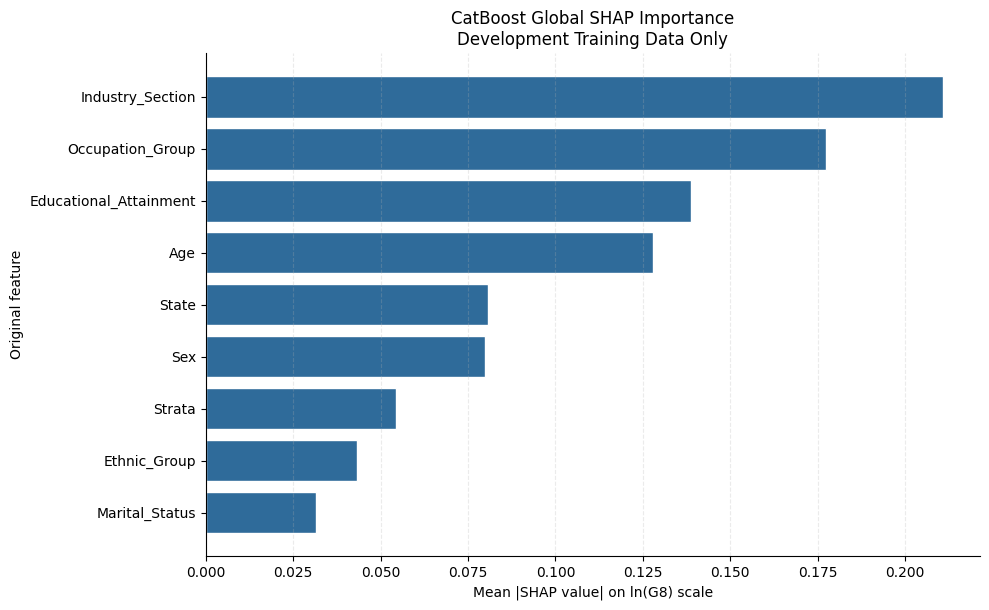


SECTION 7 DEVELOPMENT SHAP RESULT
Rows explained: 21940
Features explained: 9
SHAP scale: ln(G8)
Maximum additivity error: 7.105427357601002e-15
Maximum inverse-transform error: 0.0
Held-out data used: False

Global feature importance:
 Rank                Feature  Mean Absolute SHAP on ln(G8)  Relative Importance (%)
    1       Industry_Section                      0.210886                22.318844
    2       Occupation_Group                      0.177382                18.773023
    3 Educational_Attainment                      0.138909                14.701229
    4                    Age                      0.127913                13.537466
    5                  State                      0.080678                 8.538447
    6                    Sex                      0.079914                 8.457561
    7                 Strata                      0.054500                 5.767939
    8           Ethnic_Group                      0.043143                 4.565982
    9  

In [13]:
# ============================================================
# Section 7 - Development-Only Native CatBoost SHAP
# ============================================================

import hashlib
import json
import joblib
import time

from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from catboost import Pool


# ------------------------------------------------------------
# 0. Hard development-phase guard
# ------------------------------------------------------------

ANALYSIS_PHASE = "development"


if ANALYSIS_PHASE != "development":
    raise RuntimeError(
        "This section is restricted to the "
        "development phase."
    )


required_objects = [
    "PROTOCOL",
    "OUTPUT_DIR",
    "DATA_SHA256",
    "X_train",
    "y_train",
    "EXPECTED_MODEL_FEATURES",
    "CATBOOST_CATEGORICAL_FEATURES",
    "prepare_catboost_frame",
]


missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]


if missing_objects:
    raise RuntimeError(
        "Run Sections 1-6 first. Missing: "
        + ", ".join(missing_objects)
    )


if not X_train.index.equals(
    y_train.index
):
    raise RuntimeError(
        "X_train and y_train indices "
        "are not aligned."
    )


if list(X_train.columns) != list(
    EXPECTED_MODEL_FEATURES
):
    raise RuntimeError(
        "X_train feature columns or order "
        "have changed."
    )


# ------------------------------------------------------------
# 1. Fixed model and SHAP output paths
# ------------------------------------------------------------

FINAL_MODEL_DIR = (
    Path(OUTPUT_DIR)
    / "final_model_development"
)


FINAL_MODEL_FILE = (
    FINAL_MODEL_DIR
    / "final_estimator.joblib"
)


FINAL_SEARCH_COMPLETION_FILE = (
    FINAL_MODEL_DIR
    / "final_search_complete.json"
)


SHAP_OUTPUT_DIR = (
    Path(OUTPUT_DIR)
    / "development_shap"
)


SHAP_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


SHAP_VALUES_FILE = (
    SHAP_OUTPUT_DIR
    / "full_training_shap_values.csv"
)


SHAP_IMPORTANCE_FILE = (
    SHAP_OUTPUT_DIR
    / "global_shap_importance.csv"
)


SHAP_FIGURE_FILE = (
    SHAP_OUTPUT_DIR
    / "shap_global_importance.png"
)


SHAP_COMPLETION_FILE = (
    SHAP_OUTPUT_DIR
    / "shap_complete.json"
)


for required_path in [
    FINAL_MODEL_FILE,
    FINAL_SEARCH_COMPLETION_FILE,
]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Missing required file: "
            f"{required_path}"
        )


# ------------------------------------------------------------
# 2. Helper functions
# ------------------------------------------------------------

def index_fingerprint(index):
    payload = ",".join(
        map(str, index.tolist())
    ).encode("utf-8")

    return hashlib.sha256(
        payload
    ).hexdigest()


def file_fingerprint(file_path):
    hasher = hashlib.sha256()

    with Path(file_path).open(
        "rb"
    ) as file:

        for chunk in iter(
            lambda: file.read(
                1024 * 1024
            ),
            b"",
        ):
            hasher.update(chunk)

    return hasher.hexdigest()


def make_json_safe(value):

    if isinstance(value, dict):
        return {
            str(key):
                make_json_safe(item)

            for key, item
            in value.items()
        }

    if isinstance(value, (list, tuple)):
        return [
            make_json_safe(item)
            for item in value
        ]

    if isinstance(value, np.generic):
        return value.item()

    if isinstance(value, Path):
        return str(value)

    return value


def atomic_write_csv(
    dataframe,
    output_path,
):
    output_path = Path(output_path)

    temporary_path = Path(
        str(output_path) + ".tmp"
    )

    dataframe.to_csv(
        temporary_path,
        index=False,
    )

    temporary_path.replace(
        output_path
    )


def atomic_write_json(
    payload,
    output_path,
):
    output_path = Path(output_path)

    temporary_path = Path(
        str(output_path) + ".tmp"
    )

    with temporary_path.open(
        "w",
        encoding="utf-8",
    ) as file:

        json.dump(
            make_json_safe(payload),
            file,
            indent=4,
            ensure_ascii=False,
        )

    temporary_path.replace(
        output_path
    )


def atomic_save_figure(
    figure,
    output_path,
):
    output_path = Path(output_path)

    temporary_path = (
        output_path.parent
        / (
            output_path.stem
            + ".tmp"
            + output_path.suffix
        )
    )

    figure.savefig(
        temporary_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    temporary_path.replace(
        output_path
    )


TRAIN_INDEX_SHA256 = index_fingerprint(
    X_train.index
)


FINAL_MODEL_SHA256 = file_fingerprint(
    FINAL_MODEL_FILE
)


# ------------------------------------------------------------
# 3. Verify the saved development model
# ------------------------------------------------------------

with FINAL_SEARCH_COMPLETION_FILE.open(
    "r",
    encoding="utf-8",
) as file:

    final_search_record = json.load(file)


if final_search_record.get(
    "Experiment ID"
) != PROTOCOL["experiment_id"]:
    raise RuntimeError(
        "Final model experiment ID mismatch."
    )


if final_search_record.get(
    "Data SHA256"
) != DATA_SHA256:
    raise RuntimeError(
        "Final model data fingerprint mismatch."
    )


if final_search_record.get(
    "Train Index SHA256"
) != TRAIN_INDEX_SHA256:
    raise RuntimeError(
        "Training-index fingerprint mismatch."
    )


if final_search_record.get(
    "Training Rows"
) != len(X_train):
    raise RuntimeError(
        "Training-row count mismatch."
    )


if final_search_record.get(
    "Model"
) != "CatBoost":
    raise RuntimeError(
        "The fixed development model "
        "is not CatBoost."
    )


if final_search_record.get(
    "Target"
) != "ln(G8)":
    raise RuntimeError(
        "The fixed target approach "
        "is not ln(G8)."
    )


if final_search_record.get(
    "Model Refit On All Training Rows"
) is not True:
    raise RuntimeError(
        "The model was not confirmed as "
        "refitted on all training rows."
    )


if final_search_record.get(
    "Test Set Used"
) is not False:
    raise RuntimeError(
        "The saved development record does "
        "not confirm an untouched holdout."
    )


# ------------------------------------------------------------
# 4. Fixed SHAP analysis identity
# ------------------------------------------------------------

SHAP_ANALYSIS_IDENTITY = {
    "Experiment ID":
        PROTOCOL["experiment_id"],

    "Analysis Phase":
        ANALYSIS_PHASE,

    "Data SHA256":
        DATA_SHA256,

    "Train Index SHA256":
        TRAIN_INDEX_SHA256,

    "Final Model SHA256":
        FINAL_MODEL_SHA256,

    "Rows Explained":
        int(len(X_train)),

    "Features Explained":
        list(EXPECTED_MODEL_FEATURES),

    "Model":
        final_search_record["Model"],

    "Target":
        final_search_record["Target"],

    "SHAP Method":
        "CatBoost native ShapValues",

    "SHAP Calculation Type":
        "Regular",

    "Model Output":
        "Raw",

    "SHAP Scale":
        "ln(G8)",

    "Held-Out Data Used":
        False,
}


# ------------------------------------------------------------
# 5. Reuse an identical completed SHAP run
# ------------------------------------------------------------

shap_already_complete = False


if SHAP_COMPLETION_FILE.exists():

    with SHAP_COMPLETION_FILE.open(
        "r",
        encoding="utf-8",
    ) as file:

        existing_shap_completion = (
            json.load(file)
        )


    for key, expected_value in (
        SHAP_ANALYSIS_IDENTITY.items()
    ):

        if existing_shap_completion.get(
            key
        ) != expected_value:

            raise RuntimeError(
                "An incompatible SHAP result "
                f"already exists. Mismatch: {key}. "
                "Do not overwrite it."
            )


    for required_output in [
        SHAP_VALUES_FILE,
        SHAP_IMPORTANCE_FILE,
        SHAP_FIGURE_FILE,
    ]:

        if not required_output.exists():
            raise FileNotFoundError(
                "SHAP completion marker exists, "
                f"but output is missing: "
                f"{required_output}"
            )


    shap_already_complete = True


# ------------------------------------------------------------
# 6. Load and inspect the frozen estimator
# ------------------------------------------------------------

FIXED_DEVELOPMENT_ESTIMATOR = joblib.load(
    FINAL_MODEL_FILE
)


if not hasattr(
    FIXED_DEVELOPMENT_ESTIMATOR,
    "regressor_",
):
    raise RuntimeError(
        "Expected a fitted "
        "TransformedTargetRegressor."
    )


fitted_pipeline = (
    FIXED_DEVELOPMENT_ESTIMATOR
    .regressor_
)


if not hasattr(
    fitted_pipeline,
    "named_steps",
):
    raise RuntimeError(
        "The fitted regressor is not "
        "the expected pipeline."
    )


if set(
    fitted_pipeline.named_steps
) != {
    "preprocessing",
    "model",
}:
    raise RuntimeError(
        "Unexpected fitted pipeline steps."
    )


fixed_preprocessor = (
    fitted_pipeline
    .named_steps["preprocessing"]
)


fixed_catboost_model = (
    fitted_pipeline
    .named_steps["model"]
)


if not fixed_catboost_model.is_fitted():
    raise RuntimeError(
        "The CatBoost model is not fitted."
    )


model_feature_names = list(
    fixed_catboost_model.feature_names_
)


if model_feature_names != list(
    EXPECTED_MODEL_FEATURES
):
    raise RuntimeError(
        "CatBoost feature names or order "
        "do not match the verified design."
    )


categorical_indices = (
    fixed_catboost_model
    .get_cat_feature_indices()
)


model_categorical_names = [
    model_feature_names[index]
    for index in categorical_indices
]


if model_categorical_names != list(
    CATBOOST_CATEGORICAL_FEATURES
):
    raise RuntimeError(
        "CatBoost categorical-feature "
        "metadata has changed."
    )


# Verify that the stored model still contains
# the selected Section 6 hyperparameters.
loaded_parameters = (
    FIXED_DEVELOPMENT_ESTIMATOR
    .get_params(deep=True)
)


for parameter_name, expected_value in (
    final_search_record[
        "Best Params"
    ].items()
):

    if parameter_name not in loaded_parameters:
        raise RuntimeError(
            "Saved estimator is missing "
            f"parameter: {parameter_name}"
        )

    loaded_value = loaded_parameters[
        parameter_name
    ]

    if isinstance(
        expected_value,
        (int, float),
    ):

        if not np.isclose(
            float(loaded_value),
            float(expected_value),
            rtol=1e-12,
            atol=1e-12,
        ):
            raise RuntimeError(
                "Saved estimator parameter "
                f"mismatch: {parameter_name}"
            )

    elif loaded_value != expected_value:

        raise RuntimeError(
            "Saved estimator parameter "
            f"mismatch: {parameter_name}"
        )


# ------------------------------------------------------------
# 7. Calculate full-training native SHAP values
# ------------------------------------------------------------

if shap_already_complete:

    print(
        "An identical development SHAP "
        "analysis is already complete."
    )

    print(
        "The SHAP calculation will not "
        "be repeated."
    )


    DEVELOPMENT_SHAP_VALUES = pd.read_csv(
        SHAP_VALUES_FILE
    )


    GLOBAL_SHAP_IMPORTANCE = pd.read_csv(
        SHAP_IMPORTANCE_FILE
    )


    SHAP_SUMMARY = (
        existing_shap_completion
    )


else:

    print(
        "Starting development-only "
        "CatBoost SHAP analysis."
    )

    print(
        "Rows:",
        len(X_train),
    )

    print(
        "Features:",
        len(EXPECTED_MODEL_FEATURES),
    )

    print(
        "SHAP scale: ln(G8)"
    )

    print(
        "Held-out data used: False",
        flush=True,
    )


    # This transformer only applies the fixed
    # rule-based dtype preparation used by CatBoost.
    prepared_training_frame = (
        fixed_preprocessor.transform(
            X_train
        )
    )


    if not isinstance(
        prepared_training_frame,
        pd.DataFrame,
    ):
        raise RuntimeError(
            "CatBoost preprocessing did not "
            "return a DataFrame."
        )


    if list(
        prepared_training_frame.columns
    ) != list(
        EXPECTED_MODEL_FEATURES
    ):
        raise RuntimeError(
            "Prepared feature columns or order "
            "have changed."
        )


    development_pool = Pool(
        data=prepared_training_frame,

        cat_features=list(
            CATBOOST_CATEGORICAL_FEATURES
        ),
    )


    shap_start = time.perf_counter()


    native_shap_output = (
        fixed_catboost_model
        .get_feature_importance(
            data=development_pool,

            type="ShapValues",

            thread_count=-1,

            verbose=False,

            shap_mode="Auto",

            model_output="Raw",

            shap_calc_type="Regular",
        )
    )


    shap_seconds = (
        time.perf_counter()
        - shap_start
    )


    native_shap_output = np.asarray(
        native_shap_output,
        dtype=float,
    )


    expected_shape = (
        len(X_train),
        len(EXPECTED_MODEL_FEATURES) + 1,
    )


    if (
        native_shap_output.shape
        != expected_shape
    ):
        raise RuntimeError(
            "Unexpected CatBoost SHAP shape: "
            f"{native_shap_output.shape}; "
            f"expected {expected_shape}."
        )


    if not np.isfinite(
        native_shap_output
    ).all():
        raise RuntimeError(
            "Non-finite SHAP values found."
        )


    shap_contributions = (
        native_shap_output[
            :,
            :-1,
        ]
    )


    expected_values = (
        native_shap_output[
            :,
            -1,
        ]
    )


    # Native CatBoost prediction before exp().
    predicted_log_g8 = np.asarray(
        fixed_catboost_model.predict(
            development_pool,

            prediction_type=
                "RawFormulaVal",

            thread_count=-1,
        ),
        dtype=float,
    )


    reconstructed_log_g8 = (
        expected_values
        + shap_contributions.sum(
            axis=1
        )
    )


    additivity_errors = np.abs(
        reconstructed_log_g8
        - predicted_log_g8
    )


    maximum_additivity_error = float(
        additivity_errors.max()
    )


    mean_additivity_error = float(
        additivity_errors.mean()
    )


    if maximum_additivity_error > 1e-8:
        raise RuntimeError(
            "SHAP additivity check failed. "
            "Maximum log-scale error: "
            f"{maximum_additivity_error}"
        )


    # The complete estimator automatically
    # applies exp() after predicting ln(G8).
    pipeline_predictions_rm = np.asarray(
        FIXED_DEVELOPMENT_ESTIMATOR.predict(
            X_train
        ),
        dtype=float,
    )


    reconstructed_predictions_rm = np.exp(
        predicted_log_g8
    )


    inverse_transform_errors = np.abs(
        reconstructed_predictions_rm
        - pipeline_predictions_rm
    )


    maximum_inverse_transform_error = float(
        inverse_transform_errors.max()
    )


    if maximum_inverse_transform_error > 1e-8:
        raise RuntimeError(
            "The ln(G8)-to-RM transformation "
            "check failed."
        )


    if not np.allclose(
        expected_values,
        expected_values[0],
        rtol=1e-12,
        atol=1e-12,
    ):
        raise RuntimeError(
            "CatBoost returned inconsistent "
            "SHAP expected values."
        )


    # --------------------------------------------------------
    # Full row-level SHAP output
    # --------------------------------------------------------

    shap_column_names = [
        f"SHAP__{feature_name}"

        for feature_name
        in EXPECTED_MODEL_FEATURES
    ]


    DEVELOPMENT_SHAP_VALUES = (
        pd.DataFrame(
            shap_contributions,

            columns=shap_column_names,

            index=X_train.index,
        )
        .reset_index()
    )


    if (
        DEVELOPMENT_SHAP_VALUES
        .columns[0]
        != "source_row_id"
    ):
        DEVELOPMENT_SHAP_VALUES = (
            DEVELOPMENT_SHAP_VALUES
            .rename(
                columns={
                    DEVELOPMENT_SHAP_VALUES
                    .columns[0]:
                        "source_row_id"
                }
            )
        )


    DEVELOPMENT_SHAP_VALUES[
        "Expected ln(G8)"
    ] = expected_values


    DEVELOPMENT_SHAP_VALUES[
        "Predicted ln(G8)"
    ] = predicted_log_g8


    DEVELOPMENT_SHAP_VALUES[
        "Predicted G8 (RM)"
    ] = pipeline_predictions_rm


    DEVELOPMENT_SHAP_VALUES[
        "Additivity Error"
    ] = additivity_errors


    if DEVELOPMENT_SHAP_VALUES[
        "source_row_id"
    ].duplicated().any():
        raise RuntimeError(
            "Duplicate source-row IDs found "
            "in SHAP output."
        )


    if not pd.Index(
        DEVELOPMENT_SHAP_VALUES[
            "source_row_id"
        ]
    ).equals(
        X_train.index
    ):
        raise RuntimeError(
            "SHAP output row order does not "
            "match X_train."
        )


    # --------------------------------------------------------
    # Global SHAP importance
    # --------------------------------------------------------

    mean_absolute_shap = np.mean(
        np.abs(
            shap_contributions
        ),
        axis=0,
    )


    mean_signed_shap = np.mean(
        shap_contributions,
        axis=0,
    )


    shap_standard_deviation = np.std(
        shap_contributions,
        axis=0,
        ddof=1,
    )


    GLOBAL_SHAP_IMPORTANCE = pd.DataFrame({
        "Feature":
            EXPECTED_MODEL_FEATURES,

        "Mean Absolute SHAP on ln(G8)":
            mean_absolute_shap,

        "Mean Signed SHAP on ln(G8)":
            mean_signed_shap,

        "SHAP SD on ln(G8)":
            shap_standard_deviation,
    })


    total_mean_absolute_shap = float(
        GLOBAL_SHAP_IMPORTANCE[
            "Mean Absolute SHAP on ln(G8)"
        ].sum()
    )


    if (
        not np.isfinite(
            total_mean_absolute_shap
        )
        or total_mean_absolute_shap <= 0
    ):
        raise RuntimeError(
            "Invalid total SHAP importance."
        )


    GLOBAL_SHAP_IMPORTANCE[
        "Relative Importance (%)"
    ] = (
        100.0
        * GLOBAL_SHAP_IMPORTANCE[
            "Mean Absolute SHAP on ln(G8)"
        ]
        / total_mean_absolute_shap
    )


    GLOBAL_SHAP_IMPORTANCE = (
        GLOBAL_SHAP_IMPORTANCE
        .sort_values(
            "Mean Absolute SHAP on ln(G8)",
            ascending=False,
        )
        .reset_index(drop=True)
    )


    GLOBAL_SHAP_IMPORTANCE.insert(
        0,
        "Rank",
        np.arange(
            1,
            len(
                GLOBAL_SHAP_IMPORTANCE
            ) + 1,
        ),
    )


    # --------------------------------------------------------
    # Global-importance figure
    # --------------------------------------------------------

    plot_data = (
        GLOBAL_SHAP_IMPORTANCE
        .sort_values(
            "Mean Absolute SHAP on ln(G8)",
            ascending=True,
        )
    )


    figure, axis = plt.subplots(
        figsize=(10, 6.2)
    )


    axis.barh(
        plot_data["Feature"],

        plot_data[
            "Mean Absolute SHAP on ln(G8)"
        ],

        color="#2F6B9A",

        edgecolor="white",
    )


    axis.set_xlabel(
        "Mean |SHAP value| on ln(G8) scale"
    )


    axis.set_ylabel(
        "Original feature"
    )


    axis.set_title(
        "CatBoost Global SHAP Importance\n"
        "Development Training Data Only"
    )


    axis.grid(
        axis="x",
        linestyle="--",
        alpha=0.25,
    )


    axis.spines[
        "top"
    ].set_visible(False)


    axis.spines[
        "right"
    ].set_visible(False)


    figure.tight_layout()


    # --------------------------------------------------------
    # Save SHAP outputs
    # --------------------------------------------------------

    atomic_write_csv(
        DEVELOPMENT_SHAP_VALUES,
        SHAP_VALUES_FILE,
    )


    atomic_write_csv(
        GLOBAL_SHAP_IMPORTANCE,
        SHAP_IMPORTANCE_FILE,
    )


    atomic_save_figure(
        figure,
        SHAP_FIGURE_FILE,
    )


    SHAP_SUMMARY = {
        **SHAP_ANALYSIS_IDENTITY,

        "Expected ln(G8)":
            float(expected_values[0]),

        "Maximum Additivity Error":
            maximum_additivity_error,

        "Mean Additivity Error":
            mean_additivity_error,

        "Maximum Inverse-Transform Error":
            maximum_inverse_transform_error,

        "Calculation Seconds":
            float(shap_seconds),

        "Top Feature":
            str(
                GLOBAL_SHAP_IMPORTANCE.loc[
                    0,
                    "Feature",
                ]
            ),

        "Performance Evaluation":
            False,

        "Causal Interpretation":
            False,

        "Completed UTC":
            datetime.now(
                timezone.utc
            ).isoformat(),
    }


    # Completion marker is written last.
    atomic_write_json(
        SHAP_SUMMARY,
        SHAP_COMPLETION_FILE,
    )


    print(
        "Development SHAP analysis "
        "completed and saved."
    )


    plt.show()


# ------------------------------------------------------------
# 8. Display verified SHAP results
# ------------------------------------------------------------

print("\n" + "=" * 70)

print(
    "SECTION 7 DEVELOPMENT SHAP RESULT"
)

print("=" * 70)


print(
    "Rows explained:",
    SHAP_SUMMARY[
        "Rows Explained"
    ],
)


print(
    "Features explained:",
    len(
        SHAP_SUMMARY[
            "Features Explained"
        ]
    ),
)


print(
    "SHAP scale:",
    SHAP_SUMMARY[
        "SHAP Scale"
    ],
)


print(
    "Maximum additivity error:",
    SHAP_SUMMARY[
        "Maximum Additivity Error"
    ],
)


print(
    "Maximum inverse-transform error:",
    SHAP_SUMMARY[
        "Maximum Inverse-Transform Error"
    ],
)


print(
    "Held-out data used:",
    SHAP_SUMMARY[
        "Held-Out Data Used"
    ],
)


print(
    "\nGlobal feature importance:"
)


print(
    GLOBAL_SHAP_IMPORTANCE[
        [
            "Rank",
            "Feature",
            "Mean Absolute SHAP on ln(G8)",
            "Relative Importance (%)",
        ]
    ]
    .round(6)
    .to_string(index=False)
)


print(
    "\nSaved SHAP outputs:"
)


print(
    SHAP_OUTPUT_DIR.resolve()
)


print(
    "\nInterpretation boundary:"
)


print(
    "- SHAP values explain the fixed "
    "development model."
)


print(
    "- SHAP values are additive on the "
    "ln(G8) scale, not directly in RM."
)


print(
    "- Positive SHAP raises predicted ln(G8); "
    "negative SHAP lowers it."
)


print(
    "- Global importance does not show "
    "causality."
)


print(
    "- This training-data explanation is "
    "not a validation-performance estimate."
)


print(
    "- Nested CV OOF metrics remain the "
    "development performance evidence."
)


print(
    "\nSection 7 completed."
)

SECTION 8 DEVELOPMENT OOF DIAGNOSTICS

OOF MAE:  749.660 RM
OOF RMSE: 1579.511 RM
OOF R2:   0.5947
Mean prediction error: -197.228 RM
Median prediction error: 14.419 RM

Error by actual-wage decile:
        Label  Rows  Actual G8 Mean  Predicted G8 Mean      MAE     RMSE  Mean Prediction Error  Underprediction Rate (%)
  D1 (Lowest)  2194         935.433           1260.998  345.613  489.880                325.565                    11.167
           D2  2196        1259.927           1530.018  312.080  540.470                270.091                    19.035
           D3  2199        1463.281           1638.114  271.279  491.403                174.833                    37.517
           D4  2281        1634.769           1827.578  334.193  563.760                192.809                    39.851
           D5  2126        1897.566           2085.009  439.196  720.055                187.443                    45.249
           D6  2191        2360.012           2358.322  566.150  794.

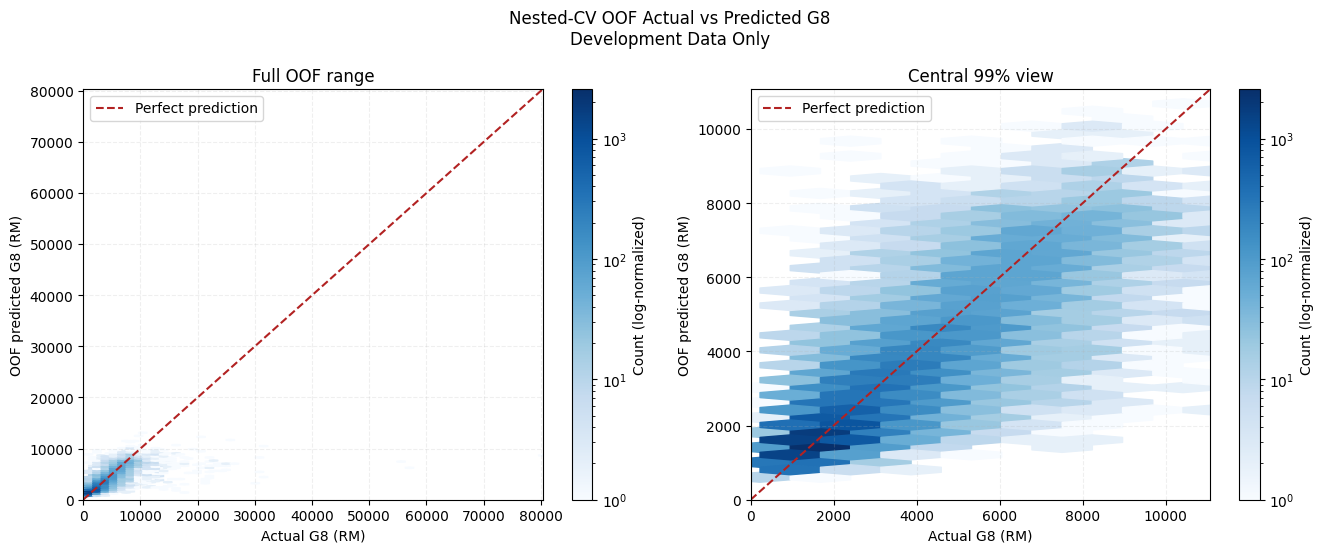

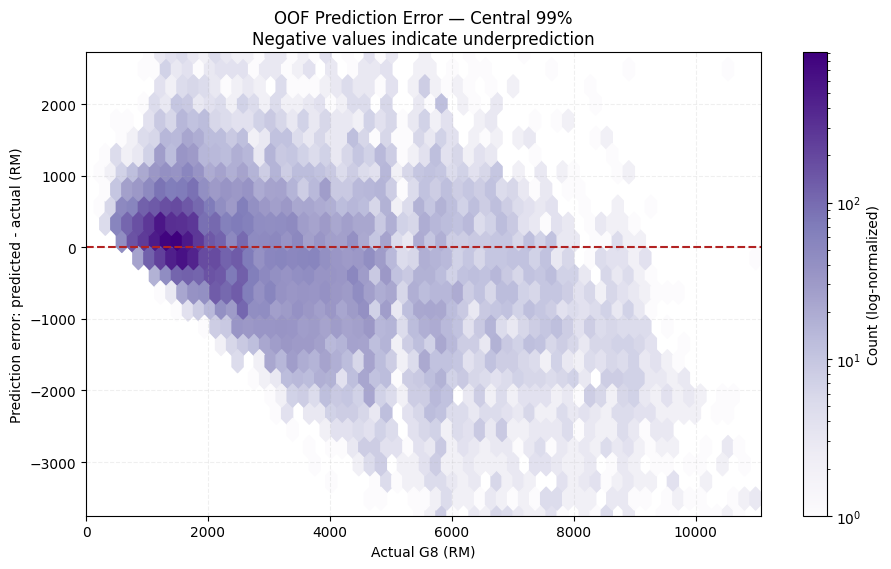

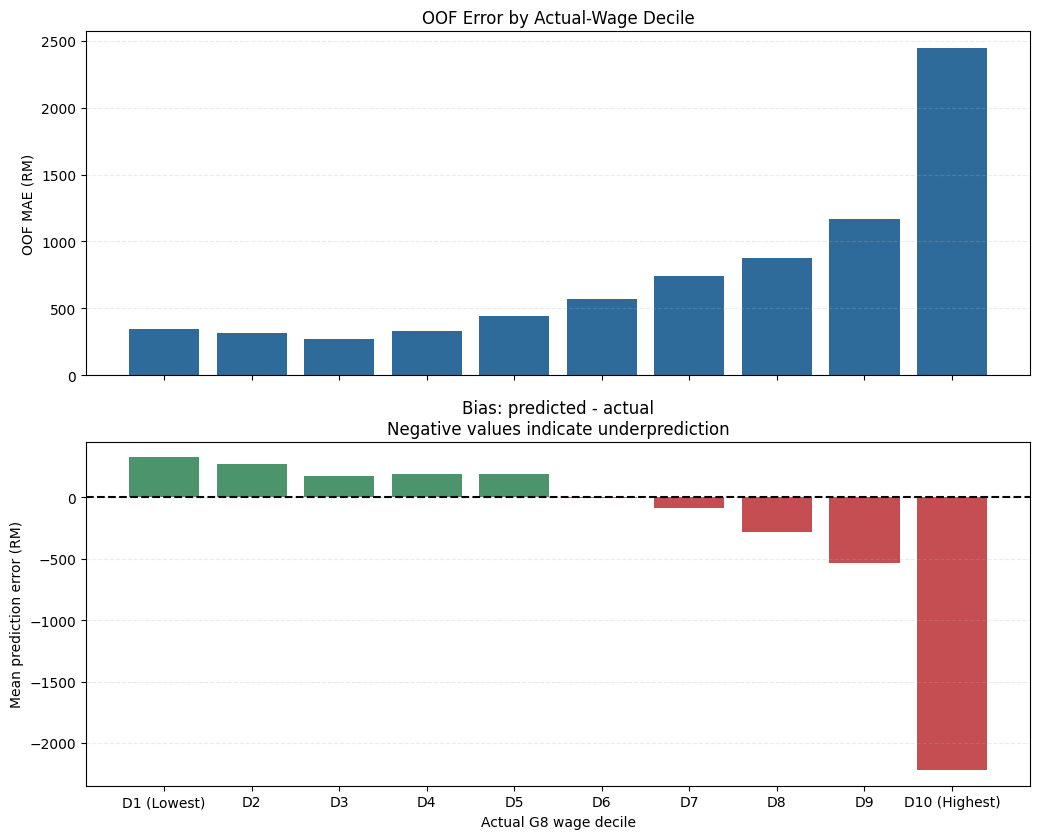

In [16]:
# ============================================================
# Section 8 - Development OOF Error Diagnostics
# ============================================================

import json
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


# ------------------------------------------------------------
# 0. Required development objects
# ------------------------------------------------------------

required_objects = [
    "PROTOCOL",
    "OUTPUT_DIR",
    "X_train",
    "y_train",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Run Sections 1-7 first. Missing: "
        + ", ".join(missing_objects)
    )

if not X_train.index.equals(y_train.index):
    raise RuntimeError(
        "X_train and y_train indices are not aligned."
    )


# ------------------------------------------------------------
# 1. Load verified OOF predictions
# ------------------------------------------------------------

section5_dir = (
    Path(OUTPUT_DIR)
    / "nested_cv_summary"
)

oof_file = (
    section5_dir
    / "oof_predictions.csv"
)

section5_summary_file = (
    section5_dir
    / "section5_summary.json"
)

output_dir = (
    Path(OUTPUT_DIR)
    / "development_oof_diagnostics"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True,
)

if not oof_file.exists():
    raise FileNotFoundError(
        f"Missing OOF predictions: {oof_file}"
    )

if not section5_summary_file.exists():
    raise FileNotFoundError(
        f"Missing Section 5 summary: "
        f"{section5_summary_file}"
    )

with section5_summary_file.open(
    "r",
    encoding="utf-8",
) as file:
    section5_summary = json.load(file)

if section5_summary.get("Status") != "Passed":
    raise RuntimeError(
        "Section 5 integrity audit did not pass."
    )

if section5_summary.get(
    "Test Set Used"
) is not False:
    raise RuntimeError(
        "Section 5 does not confirm an "
        "untouched holdout."
    )

oof = pd.read_csv(oof_file)

required_columns = {
    "source_row_id",
    "Outer Fold",
    "Actual G8",
    "Predicted G8",
    "Residual",
    "Absolute Error",
}

missing_columns = sorted(
    required_columns
    - set(oof.columns)
)

if missing_columns:
    raise KeyError(
        f"OOF file is missing: {missing_columns}"
    )


# ------------------------------------------------------------
# 2. OOF integrity checks
# ------------------------------------------------------------

if len(oof) != len(X_train):
    raise RuntimeError(
        "OOF row count does not equal "
        "the X_train row count."
    )

if oof["source_row_id"].duplicated().any():
    raise RuntimeError(
        "Duplicate source_row_id values "
        "found in OOF predictions."
    )

if set(oof["source_row_id"]) != set(X_train.index):
    raise RuntimeError(
        "OOF predictions do not cover "
        "X_train exactly once."
    )

if set(oof["Outer Fold"].astype(int)) != {
    1, 2, 3, 4, 5
}:
    raise RuntimeError(
        "Unexpected outer-fold labels."
    )

oof_index = pd.Index(
    oof["source_row_id"]
)

expected_actual = (
    y_train.loc[oof_index]
    .to_numpy(dtype=float)
)

actual = (
    oof["Actual G8"]
    .to_numpy(dtype=float)
)

predicted = (
    oof["Predicted G8"]
    .to_numpy(dtype=float)
)

if not np.allclose(
    actual,
    expected_actual,
    rtol=1e-10,
    atol=1e-8,
):
    raise RuntimeError(
        "OOF Actual G8 does not match y_train."
    )

if not np.isfinite(actual).all():
    raise RuntimeError(
        "Non-finite actual values found."
    )

if not np.isfinite(predicted).all():
    raise RuntimeError(
        "Non-finite OOF predictions found."
    )

residual = actual - predicted

if not np.allclose(
    oof["Residual"],
    residual,
):
    raise RuntimeError(
        "Saved residual values are inconsistent."
    )

if not np.allclose(
    oof["Absolute Error"],
    np.abs(residual),
):
    raise RuntimeError(
        "Saved absolute errors are inconsistent."
    )

# Positive = overprediction.
# Negative = underprediction.
oof["Prediction Error"] = (
    predicted - actual
)


# ------------------------------------------------------------
# 3. Recompute overall OOF performance
# ------------------------------------------------------------

oof_mae = float(
    mean_absolute_error(
        actual,
        predicted,
    )
)

oof_rmse = float(
    np.sqrt(
        mean_squared_error(
            actual,
            predicted,
        )
    )
)

oof_r2 = float(
    r2_score(
        actual,
        predicted,
    )
)

mean_error = float(
    oof["Prediction Error"].mean()
)

median_error = float(
    oof["Prediction Error"].median()
)

saved_metrics = (
    section5_summary["OOF Metrics"]
)

for name, value in {
    "MAE": oof_mae,
    "RMSE": oof_rmse,
    "R2": oof_r2,
}.items():

    if not np.isclose(
        float(saved_metrics[name]),
        value,
        rtol=1e-10,
        atol=1e-8,
    ):
        raise RuntimeError(
            f"OOF {name} does not match Section 5."
        )


# ------------------------------------------------------------
# 4. Actual-wage decile diagnostics
# ------------------------------------------------------------

decile_code, decile_edges = pd.qcut(
    oof["Actual G8"],
    q=10,
    labels=False,
    retbins=True,
    duplicates="drop",
)

if len(decile_edges) != 11:
    raise RuntimeError(
        "Exactly ten wage deciles "
        "could not be created."
    )

oof["Actual Wage Decile"] = (
    decile_code.astype(int) + 1
)

decile_records = []

for decile in range(1, 11):

    group = oof.loc[
        oof["Actual Wage Decile"]
        == decile
    ]

    group_actual = (
        group["Actual G8"]
        .to_numpy(dtype=float)
    )

    group_predicted = (
        group["Predicted G8"]
        .to_numpy(dtype=float)
    )

    group_error = (
        group_predicted
        - group_actual
    )

    label = f"D{decile}"

    if decile == 1:
        label += " (Lowest)"

    if decile == 10:
        label += " (Highest)"

    decile_records.append({
        "Actual Wage Decile":
            decile,

        "Label":
            label,

        "Rows":
            int(len(group)),

        "Actual G8 Minimum":
            float(group_actual.min()),

        "Actual G8 Maximum":
            float(group_actual.max()),

        "Actual G8 Mean":
            float(group_actual.mean()),

        "Predicted G8 Mean":
            float(group_predicted.mean()),

        "MAE":
            float(
                mean_absolute_error(
                    group_actual,
                    group_predicted,
                )
            ),

        "RMSE":
            float(
                np.sqrt(
                    mean_squared_error(
                        group_actual,
                        group_predicted,
                    )
                )
            ),

        "Mean Prediction Error":
            float(group_error.mean()),

        "Underprediction Rate (%)":
            float(
                100
                * np.mean(
                    group_predicted
                    < group_actual
                )
            ),
    })

decile_table = pd.DataFrame(
    decile_records
)


# ------------------------------------------------------------
# 5. Figure 1: actual versus predicted
# ------------------------------------------------------------

full_limit = float(
    max(
        actual.max(),
        predicted.max(),
    )
)

zoom_limit = float(
    max(
        np.quantile(actual, 0.99),
        np.quantile(predicted, 0.99),
    )
)

fig1, axes1 = plt.subplots(
    1,
    2,
    figsize=(13.5, 5.6),
)

for axis, limit, title in [
    (
        axes1[0],
        full_limit,
        "Full OOF range",
    ),
    (
        axes1[1],
        zoom_limit,
        "Central 99% view",
    ),
]:

    hexbin = axis.hexbin(
        actual,
        predicted,
        gridsize=55,
        bins="log",
        mincnt=1,
        cmap="Blues",
    )

    axis.plot(
        [0, limit],
        [0, limit],
        "--",
        color="#B22222",
        label="Perfect prediction",
    )

    axis.set_xlim(0, limit)
    axis.set_ylim(0, limit)

    axis.set_xlabel(
        "Actual G8 (RM)"
    )

    axis.set_ylabel(
        "OOF predicted G8 (RM)"
    )

    axis.set_title(title)
    axis.legend()

    axis.grid(
        linestyle="--",
        alpha=0.2,
    )

    colorbar = fig1.colorbar(
        hexbin,
        ax=axis,
    )

    colorbar.set_label(
        "Count (log-normalized)"
    )

fig1.suptitle(
    "Nested-CV OOF Actual vs Predicted G8\n"
    "Development Data Only"
)

fig1.tight_layout()


# ------------------------------------------------------------
# 6. Figure 2: prediction error versus actual
# ------------------------------------------------------------

prediction_error = (
    predicted - actual
)

actual_99 = float(
    np.quantile(actual, 0.99)
)

central_mask = (
    actual <= actual_99
)

central_error = (
    prediction_error[central_mask]
)

error_low, error_high = np.quantile(
    central_error,
    [0.01, 0.99],
)

fig2, axis2 = plt.subplots(
    figsize=(9.5, 5.8)
)

hexbin2 = axis2.hexbin(
    actual[central_mask],
    central_error,
    gridsize=60,
    bins="log",
    mincnt=1,
    cmap="Purples",
)

axis2.axhline(
    0,
    linestyle="--",
    color="#B22222",
)

axis2.set_xlim(
    0,
    actual_99,
)

axis2.set_ylim(
    error_low,
    error_high,
)

axis2.set_xlabel(
    "Actual G8 (RM)"
)

axis2.set_ylabel(
    "Prediction error: predicted - actual (RM)"
)

axis2.set_title(
    "OOF Prediction Error — Central 99%\n"
    "Negative values indicate underprediction"
)

axis2.grid(
    linestyle="--",
    alpha=0.2,
)

colorbar2 = fig2.colorbar(
    hexbin2,
    ax=axis2,
)

colorbar2.set_label(
    "Count (log-normalized)"
)

fig2.tight_layout()


# ------------------------------------------------------------
# 7. Figure 3: error by wage decile
# ------------------------------------------------------------

fig3, axes3 = plt.subplots(
    2,
    1,
    figsize=(10.5, 8.5),
    sharex=True,
)

axes3[0].bar(
    decile_table["Label"],
    decile_table["MAE"],
    color="#2F6B9A",
)

axes3[0].set_ylabel(
    "OOF MAE (RM)"
)

axes3[0].set_title(
    "OOF Error by Actual-Wage Decile"
)

axes3[0].grid(
    axis="y",
    linestyle="--",
    alpha=0.25,
)

bias = (
    decile_table[
        "Mean Prediction Error"
    ]
)

bias_colours = [
    "#C44E52"
    if value < 0
    else "#4C956C"
    for value in bias
]

axes3[1].bar(
    decile_table["Label"],
    bias,
    color=bias_colours,
)

axes3[1].axhline(
    0,
    linestyle="--",
    color="black",
)

axes3[1].set_ylabel(
    "Mean prediction error (RM)"
)

axes3[1].set_xlabel(
    "Actual G8 wage decile"
)

axes3[1].set_title(
    "Bias: predicted - actual\n"
    "Negative values indicate underprediction"
)

axes3[1].grid(
    axis="y",
    linestyle="--",
    alpha=0.25,
)

fig3.tight_layout()


# ------------------------------------------------------------
# 8. Save diagnostic outputs
# ------------------------------------------------------------

oof.to_csv(
    output_dir
    / "oof_predictions_with_deciles.csv",
    index=False,
)

decile_table.to_csv(
    output_dir
    / "oof_error_by_actual_wage_decile.csv",
    index=False,
)

fig1.savefig(
    output_dir
    / "oof_actual_vs_predicted.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

fig2.savefig(
    output_dir
    / "oof_prediction_error_vs_actual.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

fig3.savefig(
    output_dir
    / "oof_error_by_wage_decile.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

summary = {
    "Experiment ID":
        PROTOCOL["experiment_id"],

    "Analysis Phase":
        "development",

    "Rows":
        int(len(oof)),

    "OOF MAE":
        oof_mae,

    "OOF RMSE":
        oof_rmse,

    "OOF R2":
        oof_r2,

    "Mean Prediction Error":
        mean_error,

    "Median Prediction Error":
        median_error,

    "Lowest-Decile Mean Error":
        float(
            decile_table.iloc[0][
                "Mean Prediction Error"
            ]
        ),

    "Highest-Decile Mean Error":
        float(
            decile_table.iloc[-1][
                "Mean Prediction Error"
            ]
        ),

    "Highest-Decile MAE":
        float(
            decile_table.iloc[-1][
                "MAE"
            ]
        ),

    "Actual G8 Maximum":
        float(actual.max()),

    "Predicted G8 Maximum":
        float(predicted.max()),

    "Held-Out Data Used":
        False,

    "Model Training Performed":
        False,

    "Hyperparameter Tuning Performed":
        False,

    "Completed UTC":
        datetime.now(
            timezone.utc
        ).isoformat(),
}

with (
    output_dir
    / "oof_diagnostics_complete.json"
).open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False,
    )


# ------------------------------------------------------------
# 9. Display results
# ------------------------------------------------------------

print(
    "SECTION 8 DEVELOPMENT OOF DIAGNOSTICS"
)

print(
    f"\nOOF MAE:  {oof_mae:.3f} RM"
)

print(
    f"OOF RMSE: {oof_rmse:.3f} RM"
)

print(
    f"OOF R2:   {oof_r2:.4f}"
)

print(
    f"Mean prediction error: "
    f"{mean_error:.3f} RM"
)

print(
    f"Median prediction error: "
    f"{median_error:.3f} RM"
)

print(
    "\nError by actual-wage decile:"
)

print(
    decile_table[
        [
            "Label",
            "Rows",
            "Actual G8 Mean",
            "Predicted G8 Mean",
            "MAE",
            "RMSE",
            "Mean Prediction Error",
            "Underprediction Rate (%)",
        ]
    ]
    .round(3)
    .to_string(index=False)
)

print(
    "\nHeld-out data used: False"
)

print(
    "Model training performed: False"
)

print(
    "Hyperparameter tuning performed: False"
)

print(
    "\nSaved outputs:"
)

print(
    output_dir.resolve()
)

print(
    "\nSection 8 completed."
)

plt.show()

SECTION 9 DEVELOPMENT DIRECTIONAL SHAP

Industry Section:
                     Industry Label    N  Mean_SHAP  Median_SHAP  P10_SHAP  P90_SHAP         Direction  Small Sample Flag
             B – Mining & quarrying  186     0.3995       0.3886    0.3431    0.4876 Raises prediction              False
          O – Public administration 2171     0.3937       0.4001    0.2933    0.4839 Raises prediction              False
     Q – Human health & social work 1167     0.3604       0.3602    0.3056    0.4158 Raises prediction              False
                      P – Education 2380     0.3123       0.3122    0.2644    0.3527 Raises prediction              False
       D – Electricity & gas supply  176     0.1365       0.1319    0.0719    0.2045 Raises prediction              False
    J – Information & communication  321     0.0478       0.0575   -0.0158    0.1095 Raises prediction              False
          K – Financial & insurance  588     0.0473       0.0518   -0.0116    0.1005 Rai

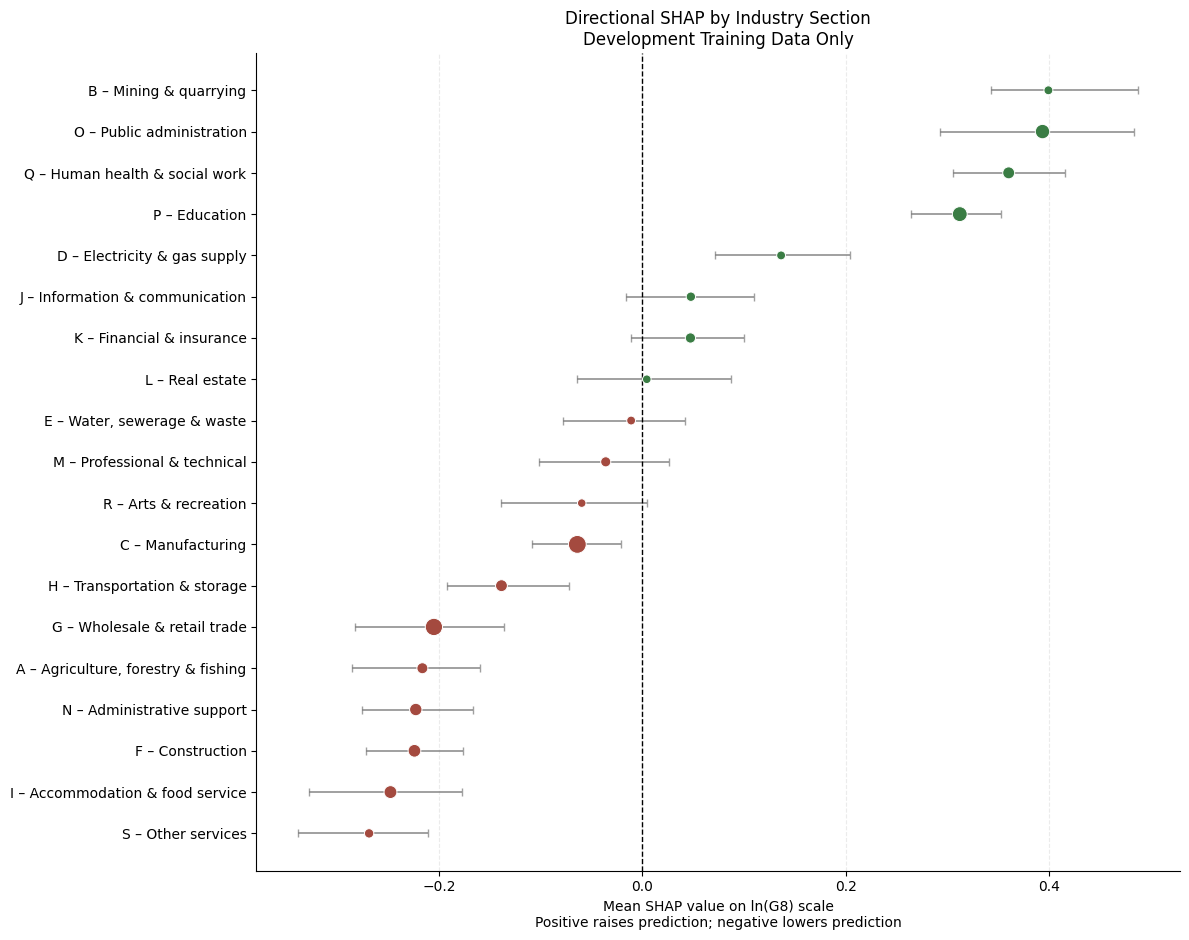

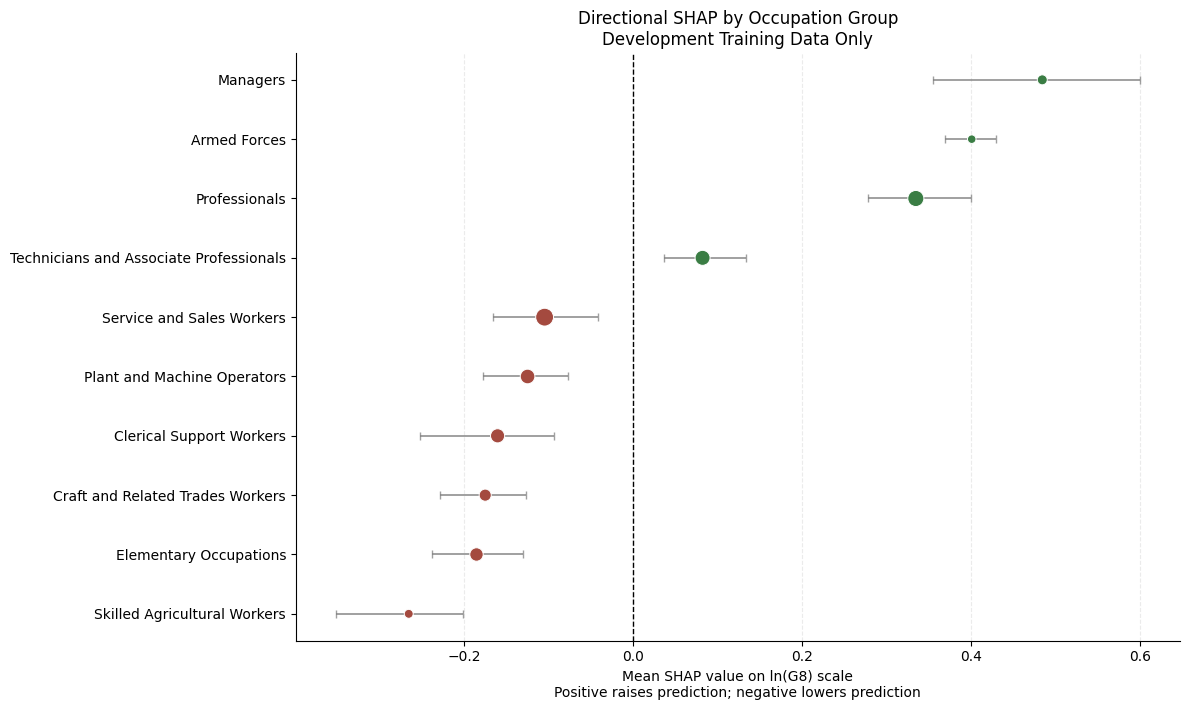

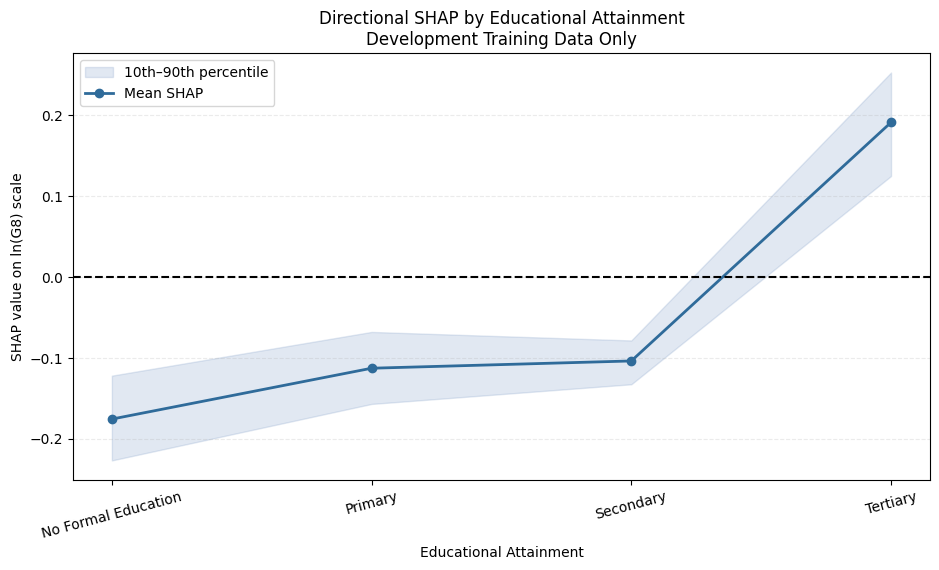

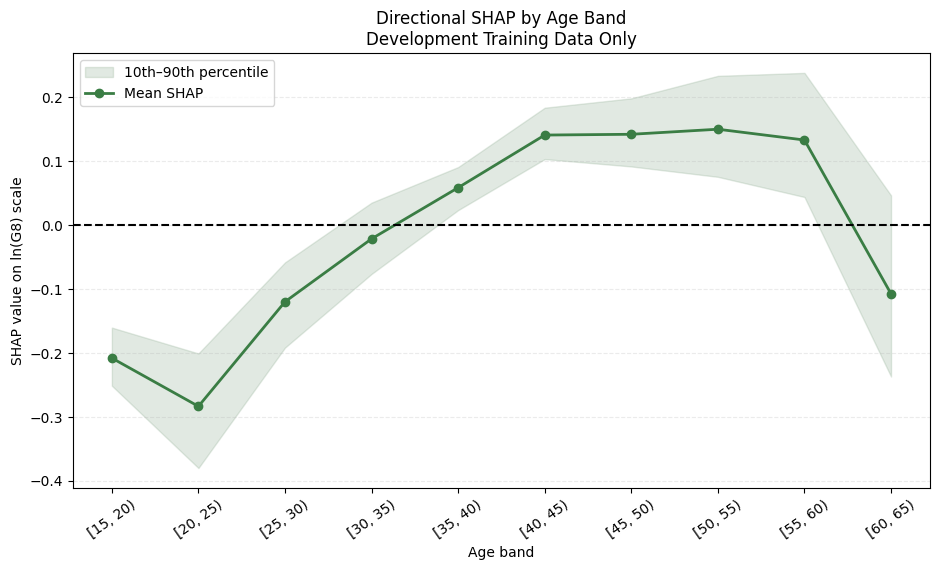

In [17]:
# ============================================================
# Section 9 - Development Directional SHAP Analysis
# ============================================================

import json
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 0. Development-only checks
# ------------------------------------------------------------

required_objects = [
    "PROTOCOL",
    "OUTPUT_DIR",
    "X_train",
    "y_train",
    "EXPECTED_MODEL_FEATURES",
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Run Sections 1-8 first. Missing: "
        + ", ".join(missing_objects)
    )

if not X_train.index.equals(y_train.index):
    raise RuntimeError(
        "X_train and y_train indices are not aligned."
    )

if list(X_train.columns) != list(
    EXPECTED_MODEL_FEATURES
):
    raise RuntimeError(
        "X_train feature columns or order changed."
    )


# ------------------------------------------------------------
# 1. Input and output files
# ------------------------------------------------------------

shap_source_dir = (
    Path(OUTPUT_DIR)
    / "development_shap"
)

shap_values_file = (
    shap_source_dir
    / "full_training_shap_values.csv"
)

shap_completion_file = (
    shap_source_dir
    / "shap_complete.json"
)

output_dir = (
    Path(OUTPUT_DIR)
    / "development_directional_shap"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True,
)

for required_path in [
    shap_values_file,
    shap_completion_file,
]:
    if not required_path.exists():
        raise FileNotFoundError(
            f"Missing required file: {required_path}"
        )


# ------------------------------------------------------------
# 2. Verify saved SHAP analysis
# ------------------------------------------------------------

with shap_completion_file.open(
    "r",
    encoding="utf-8",
) as file:
    shap_metadata = json.load(file)

if shap_metadata.get(
    "Analysis Phase"
) != "development":
    raise RuntimeError(
        "Saved SHAP analysis is not development-only."
    )

if shap_metadata.get(
    "Held-Out Data Used"
) is not False:
    raise RuntimeError(
        "Saved SHAP record does not confirm "
        "an untouched holdout."
    )

if shap_metadata.get(
    "SHAP Scale"
) != "ln(G8)":
    raise RuntimeError(
        "Unexpected SHAP output scale."
    )

if shap_metadata.get(
    "Model Output"
) != "Raw":
    raise RuntimeError(
        "Expected raw CatBoost SHAP output."
    )

if shap_metadata.get(
    "Rows Explained"
) != len(X_train):
    raise RuntimeError(
        "Saved SHAP row count mismatch."
    )


# ------------------------------------------------------------
# 3. Load and align features with SHAP values
# ------------------------------------------------------------

shap_values = pd.read_csv(
    shap_values_file
)

required_shap_columns = {
    "source_row_id",
    "SHAP__Industry_Section",
    "SHAP__Occupation_Group",
    "SHAP__Educational_Attainment",
    "SHAP__Age",
    "Additivity Error",
}

missing_shap_columns = sorted(
    required_shap_columns
    - set(shap_values.columns)
)

if missing_shap_columns:
    raise KeyError(
        f"Missing SHAP columns: {missing_shap_columns}"
    )

if len(shap_values) != len(X_train):
    raise RuntimeError(
        "SHAP row count does not equal "
        "the X_train row count."
    )

if shap_values[
    "source_row_id"
].duplicated().any():
    raise RuntimeError(
        "Duplicate source_row_id values "
        "found in SHAP output."
    )

if set(
    shap_values["source_row_id"]
) != set(
    X_train.index
):
    raise RuntimeError(
        "SHAP output does not cover "
        "X_train exactly once."
    )

if not np.isfinite(
    shap_values[
        [
            "SHAP__Industry_Section",
            "SHAP__Occupation_Group",
            "SHAP__Educational_Attainment",
            "SHAP__Age",
            "Additivity Error",
        ]
    ].to_numpy(dtype=float)
).all():
    raise RuntimeError(
        "Non-finite SHAP values found."
    )

if shap_values[
    "Additivity Error"
].max() > 1e-8:
    raise RuntimeError(
        "Saved SHAP additivity check failed."
    )

training_features = X_train.copy()

training_features.index.name = (
    "source_row_id"
)

training_features = (
    training_features
    .reset_index()
)

directional_data = (
    training_features
    .merge(
        shap_values,
        on="source_row_id",
        how="inner",
        validate="one_to_one",
        sort=False,
    )
)

if len(directional_data) != len(X_train):
    raise RuntimeError(
        "Feature/SHAP merge lost training rows."
    )


# ------------------------------------------------------------
# 4. Verified category labels
# ------------------------------------------------------------

education_labels = {
    1: "No Formal Education",
    2: "Primary",
    3: "Secondary",
    4: "Tertiary",
}

industry_labels = {
    "A": "A – Agriculture, forestry & fishing",
    "B": "B – Mining & quarrying",
    "C": "C – Manufacturing",
    "D": "D – Electricity & gas supply",
    "E": "E – Water, sewerage & waste",
    "F": "F – Construction",
    "G": "G – Wholesale & retail trade",
    "H": "H – Transportation & storage",
    "I": "I – Accommodation & food service",
    "J": "J – Information & communication",
    "K": "K – Financial & insurance",
    "L": "L – Real estate",
    "M": "M – Professional & technical",
    "N": "N – Administrative support",
    "O": "O – Public administration",
    "P": "P – Education",
    "Q": "Q – Human health & social work",
    "R": "R – Arts & recreation",
    "S": "S – Other services",
    "T": "T – Household activities",
    "U": "U – Extraterritorial bodies",
}


# ------------------------------------------------------------
# 5. Reusable grouped-SHAP summary
# ------------------------------------------------------------

def grouped_shap_summary(
    dataframe,
    group_column,
    shap_column,
):

    result = (
        dataframe
        .groupby(
            group_column,
            observed=True,
        )[shap_column]
        .agg(
            N="size",
            Mean_SHAP="mean",
            Median_SHAP="median",
            P10_SHAP=lambda values:
                values.quantile(0.10),
            P90_SHAP=lambda values:
                values.quantile(0.90),
            Mean_Absolute_SHAP=lambda values:
                np.abs(values).mean(),
        )
        .reset_index()
        .rename(
            columns={
                group_column:
                    "Category"
            }
        )
    )

    result[
        "Sample Share (%)"
    ] = (
        100.0
        * result["N"]
        / len(dataframe)
    )

    result[
        "Direction"
    ] = np.select(
        [
            result["Mean_SHAP"] > 0.01,
            result["Mean_SHAP"] < -0.01,
        ],
        [
            "Raises prediction",
            "Lowers prediction",
        ],
        default="Near zero",
    )

    result[
        "Small Sample Flag"
    ] = (
        result["N"] < 100
    )

    return result


# ------------------------------------------------------------
# 6. Industry Section summary
# ------------------------------------------------------------

industry_table = grouped_shap_summary(
    directional_data,
    "Industry_Section",
    "SHAP__Industry_Section",
)

industry_table = industry_table.rename(
    columns={
        "Category":
            "Industry Section"
    }
)

industry_table[
    "Industry Label"
] = (
    industry_table[
        "Industry Section"
    ]
    .astype(str)
    .map(industry_labels)
)

if industry_table[
    "Industry Label"
].isna().any():
    raise RuntimeError(
        "An Industry Section has no verified label."
    )

industry_table = (
    industry_table
    .sort_values(
        "Mean_SHAP",
        ascending=False,
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. Occupation Group summary
# ------------------------------------------------------------

occupation_table = grouped_shap_summary(
    directional_data,
    "Occupation_Group",
    "SHAP__Occupation_Group",
)

occupation_table = occupation_table.rename(
    columns={
        "Category":
            "Occupation Group"
    }
)

occupation_table = (
    occupation_table
    .sort_values(
        "Mean_SHAP",
        ascending=False,
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 8. Educational Attainment summary
# ------------------------------------------------------------

education_table = grouped_shap_summary(
    directional_data,
    "Educational_Attainment",
    "SHAP__Educational_Attainment",
)

education_table = education_table.rename(
    columns={
        "Category":
            "Education Code"
    }
)

education_table[
    "Education Code"
] = (
    education_table[
        "Education Code"
    ]
    .astype(int)
)

education_table[
    "Education Level"
] = (
    education_table[
        "Education Code"
    ]
    .map(education_labels)
)

if education_table[
    "Education Level"
].isna().any():
    raise RuntimeError(
        "An education code has no verified label."
    )

education_table = (
    education_table
    .sort_values(
        "Education Code"
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 9. Age-band summary
# ------------------------------------------------------------

minimum_age = int(
    directional_data["Age"].min()
)

maximum_age = int(
    directional_data["Age"].max()
)

if (
    minimum_age != 15
    or maximum_age != 64
):
    raise RuntimeError(
        "Unexpected age range: "
        f"{minimum_age}-{maximum_age}"
    )

age_edges = np.arange(
    15,
    70,
    5,
)

directional_data[
    "Age Band"
] = pd.cut(
    directional_data["Age"],
    bins=age_edges,
    right=False,
    include_lowest=True,
)

age_table = grouped_shap_summary(
    directional_data,
    "Age Band",
    "SHAP__Age",
)

age_table[
    "Age Midpoint"
] = age_table[
    "Category"
].apply(
    lambda interval:
        float(interval.mid)
)

age_table[
    "Age Band"
] = age_table[
    "Category"
].astype(str)

age_table = (
    age_table
    .drop(columns=["Category"])
    .sort_values(
        "Age Midpoint"
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 10. Plot helper for categorical features
# ------------------------------------------------------------

def categorical_interval_plot(
    table,
    label_column,
    title,
    output_path,
    figure_height,
):

    plot_data = (
        table
        .sort_values(
            "Mean_SHAP",
            ascending=True,
        )
        .reset_index(drop=True)
    )

    y_position = np.arange(
        len(plot_data)
    )

    mean_values = plot_data[
        "Mean_SHAP"
    ].to_numpy()

    lower_error = (
        mean_values
        - plot_data[
            "P10_SHAP"
        ].to_numpy()
    )

    upper_error = (
        plot_data[
            "P90_SHAP"
        ].to_numpy()
        - mean_values
    )

    point_sizes = (
        35
        + 130
        * plot_data["N"]
        / plot_data["N"].max()
    )

    figure, axis = plt.subplots(
        figsize=(12, figure_height)
    )

    axis.errorbar(
        mean_values,
        y_position,
        xerr=np.vstack(
            [
                lower_error,
                upper_error,
            ]
        ),
        fmt="none",
        ecolor="#808080",
        elinewidth=1.4,
        capsize=3,
        alpha=0.75,
    )

    colours = [
        "#3A7D44"
        if value > 0
        else "#A44A3F"
        for value in mean_values
    ]

    axis.scatter(
        mean_values,
        y_position,
        s=point_sizes,
        c=colours,
        edgecolor="white",
        linewidth=0.7,
        zorder=3,
    )

    axis.axvline(
        0,
        linestyle="--",
        color="black",
        linewidth=1,
    )

    axis.set_yticks(
        y_position
    )

    axis.set_yticklabels(
        plot_data[
            label_column
        ]
    )

    axis.set_xlabel(
        "Mean SHAP value on ln(G8) scale\n"
        "Positive raises prediction; "
        "negative lowers prediction"
    )

    axis.set_title(
        title
        + "\nDevelopment Training Data Only"
    )

    axis.grid(
        axis="x",
        linestyle="--",
        alpha=0.25,
    )

    axis.spines[
        "top"
    ].set_visible(False)

    axis.spines[
        "right"
    ].set_visible(False)

    figure.tight_layout()

    figure.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

    return figure


# ------------------------------------------------------------
# 11. Industry and occupation figures
# ------------------------------------------------------------

industry_figure = categorical_interval_plot(
    table=industry_table,
    label_column="Industry Label",
    title=(
        "Directional SHAP by "
        "Industry Section"
    ),
    output_path=(
        output_dir
        / "directional_shap_industry.png"
    ),
    figure_height=9.5,
)

occupation_figure = categorical_interval_plot(
    table=occupation_table,
    label_column="Occupation Group",
    title=(
        "Directional SHAP by "
        "Occupation Group"
    ),
    output_path=(
        output_dir
        / "directional_shap_occupation.png"
    ),
    figure_height=7.2,
)


# ------------------------------------------------------------
# 12. Education figure
# ------------------------------------------------------------

education_figure, education_axis = (
    plt.subplots(
        figsize=(9.5, 5.8)
    )
)

education_x = (
    education_table[
        "Education Code"
    ].to_numpy()
)

education_mean = (
    education_table[
        "Mean_SHAP"
    ].to_numpy()
)

education_axis.fill_between(
    education_x,
    education_table[
        "P10_SHAP"
    ],
    education_table[
        "P90_SHAP"
    ],
    color="#6C8EBF",
    alpha=0.20,
    label="10th–90th percentile",
)

education_axis.plot(
    education_x,
    education_mean,
    marker="o",
    linewidth=2,
    color="#2F6B9A",
    label="Mean SHAP",
)

education_axis.axhline(
    0,
    linestyle="--",
    color="black",
)

education_axis.set_xticks(
    education_x
)

education_axis.set_xticklabels(
    education_table[
        "Education Level"
    ],
    rotation=15,
)

education_axis.set_ylabel(
    "SHAP value on ln(G8) scale"
)

education_axis.set_xlabel(
    "Educational Attainment"
)

education_axis.set_title(
    "Directional SHAP by Educational Attainment\n"
    "Development Training Data Only"
)

education_axis.grid(
    axis="y",
    linestyle="--",
    alpha=0.25,
)

education_axis.legend()

education_figure.tight_layout()

education_figure.savefig(
    output_dir
    / "directional_shap_education.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)


# ------------------------------------------------------------
# 13. Age figure
# ------------------------------------------------------------

age_figure, age_axis = plt.subplots(
    figsize=(9.5, 5.8)
)

age_axis.fill_between(
    age_table[
        "Age Midpoint"
    ],
    age_table[
        "P10_SHAP"
    ],
    age_table[
        "P90_SHAP"
    ],
    color="#7A9E7E",
    alpha=0.22,
    label="10th–90th percentile",
)

age_axis.plot(
    age_table[
        "Age Midpoint"
    ],
    age_table[
        "Mean_SHAP"
    ],
    marker="o",
    linewidth=2,
    color="#3A7D44",
    label="Mean SHAP",
)

age_axis.axhline(
    0,
    linestyle="--",
    color="black",
)

age_axis.set_xticks(
    age_table[
        "Age Midpoint"
    ]
)

age_axis.set_xticklabels(
    age_table[
        "Age Band"
    ],
    rotation=35,
)

age_axis.set_xlabel(
    "Age band"
)

age_axis.set_ylabel(
    "SHAP value on ln(G8) scale"
)

age_axis.set_title(
    "Directional SHAP by Age Band\n"
    "Development Training Data Only"
)

age_axis.grid(
    axis="y",
    linestyle="--",
    alpha=0.25,
)

age_axis.legend()

age_figure.tight_layout()

age_figure.savefig(
    output_dir
    / "directional_shap_age.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)


# ------------------------------------------------------------
# 14. Save tables and completion record
# ------------------------------------------------------------

industry_table.to_csv(
    output_dir
    / "directional_shap_industry.csv",
    index=False,
)

occupation_table.to_csv(
    output_dir
    / "directional_shap_occupation.csv",
    index=False,
)

education_table.to_csv(
    output_dir
    / "directional_shap_education.csv",
    index=False,
)

age_table.to_csv(
    output_dir
    / "directional_shap_age.csv",
    index=False,
)

small_industry_groups = (
    industry_table.loc[
        industry_table[
            "Small Sample Flag"
        ],
        "Industry Label",
    ]
    .tolist()
)

summary = {
    "Experiment ID":
        PROTOCOL["experiment_id"],

    "Analysis Phase":
        "development",

    "Rows":
        int(len(directional_data)),

    "SHAP Scale":
        "ln(G8)",

    "Highest Mean-SHAP Industry":
        str(
            industry_table.iloc[0][
                "Industry Label"
            ]
        ),

    "Lowest Mean-SHAP Industry":
        str(
            industry_table.iloc[-1][
                "Industry Label"
            ]
        ),

    "Highest Mean-SHAP Occupation":
        str(
            occupation_table.iloc[0][
                "Occupation Group"
            ]
        ),

    "Lowest Mean-SHAP Occupation":
        str(
            occupation_table.iloc[-1][
                "Occupation Group"
            ]
        ),

    "Highest Mean-SHAP Education":
        str(
            education_table.sort_values(
                "Mean_SHAP",
                ascending=False,
            )
            .iloc[0][
                "Education Level"
            ]
        ),

    "Peak Mean-SHAP Age Band":
        str(
            age_table.sort_values(
                "Mean_SHAP",
                ascending=False,
            )
            .iloc[0][
                "Age Band"
            ]
        ),

    "Industry Groups With N Below 100":
        small_industry_groups,

    "Held-Out Data Used":
        False,

    "Model Training Performed":
        False,

    "Hyperparameter Tuning Performed":
        False,

    "Causal Interpretation":
        False,

    "Completed UTC":
        datetime.now(
            timezone.utc
        ).isoformat(),
}

with (
    output_dir
    / "directional_shap_complete.json"
).open(
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        summary,
        file,
        indent=4,
        ensure_ascii=False,
    )


# ------------------------------------------------------------
# 15. Display verified directional results
# ------------------------------------------------------------

print(
    "SECTION 9 DEVELOPMENT DIRECTIONAL SHAP"
)

print(
    "\nIndustry Section:"
)

print(
    industry_table[
        [
            "Industry Label",
            "N",
            "Mean_SHAP",
            "Median_SHAP",
            "P10_SHAP",
            "P90_SHAP",
            "Direction",
            "Small Sample Flag",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print(
    "\nOccupation Group:"
)

print(
    occupation_table[
        [
            "Occupation Group",
            "N",
            "Mean_SHAP",
            "Median_SHAP",
            "P10_SHAP",
            "P90_SHAP",
            "Direction",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print(
    "\nEducational Attainment:"
)

print(
    education_table[
        [
            "Education Code",
            "Education Level",
            "N",
            "Mean_SHAP",
            "Median_SHAP",
            "Direction",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print(
    "\nAge:"
)

print(
    age_table[
        [
            "Age Band",
            "N",
            "Mean_SHAP",
            "Median_SHAP",
            "Direction",
        ]
    ]
    .round(4)
    .to_string(index=False)
)

print(
    "\nHeld-out data used: False"
)

print(
    "Model training performed: False"
)

print(
    "Hyperparameter tuning performed: False"
)

print(
    "\nInterpretation boundary:"
)

print(
    "- Positive SHAP raises predicted ln(G8)."
)

print(
    "- Negative SHAP lowers predicted ln(G8)."
)

print(
    "- Results describe the fitted model, "
    "not causal effects."
)

print(
    "- Category-level means may also reflect "
    "interactions with other features."
)

print(
    "\nSaved outputs:"
)

print(
    output_dir.resolve()
)

print(
    "\nSection 9 completed."
)

plt.show()